# Análisis exploratorio del dataset SEED

Este notebook sirve para **entender SEED**: cómo está construido, cómo son las señales de EEG, cómo se pasa de la señal a las features `de_LDS` que usan los modelos del TFG y **dónde se ven las diferencias entre emociones positivas, neutras y negativas**.

No entrena ningún modelo. Todas las figuras se guardan también en `docs/figures/analisis_seed/`.

**Índice**

1. Cómo está construido SEED (sujetos, sesiones, películas, ficheros)
2. Los 62 electrodos y los 4 canales del TFG
3. La señal de EEG (`Preprocessed_EEG`)
4. De la señal a la feature: entropía diferencial (DE), `movingAve` y `LDS`
5. Las features `de_LDS` a lo largo de una sesión
6. Diferencias entre emociones (todos los sujetos)
7. ¿Qué features distinguen mejor las emociones?
8. Sujetos y sesiones: por qué el cross-subject es difícil
9. Resumen: datos importantes

**Requisitos.** Se ejecuta desde `notebooks/` o desde la raíz del repo, con el paquete `eeg_emotion` instalado (`pip install -e .`). Necesita `data/ExtractedFeatures_1s/` y, para las secciones 3-4, `SEED/SEED_EEG/Preprocessed_EEG/` (unos 7 GB). Tarda unos 2-3 minutos.

In [1]:
import re
import zipfile
from datetime import date
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch, Circle, Polygon, Ellipse, Rectangle
from scipy.io import loadmat, whosmat
from scipy.signal import butter, sosfiltfilt, welch, spectrogram
from scipy.interpolate import griddata
from sklearn.decomposition import PCA
from sklearn.feature_selection import f_classif

from eeg_emotion import config as cfg
from eeg_emotion import data as d

# ---------------------------------------------------------------- rutas
ROOT     = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
SEED_DIR = ROOT / "SEED" / "SEED_EEG"
PRE_DIR  = SEED_DIR / "Preprocessed_EEG"
FEAT_DIR = cfg.DATA_DIR
FIG_DIR  = ROOT / "docs" / "figures" / "analisis_seed"
FIG_DIR.mkdir(parents=True, exist_ok=True)

FS = 200                                    # Hz del EEG preprocesado
# Bandas de Zheng & Lu 2015 (las de las features de SEED)
BANDAS = {"delta": (1, 3), "theta": (4, 7), "alpha": (8, 13),
          "beta": (14, 30), "gamma": (31, 50)}
NB = list(BANDAS)
CH4 = cfg.CHANNEL_INDICES                   # FT7, FT8, T7, T8 -> 14, 22, 23, 31

# ---------------------------------------------------------------- estilo
CLASES      = [0, 1, 2]
NOMBRE      = {0: "negativa", 1: "neutra", 2: "positiva"}
COLOR       = {0: "#e34948", 1: "#eda100", 2: "#2a78d6"}   # paleta validada (CVD)
TINTA, TINTA2, MUTED, GRID, SUP = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
COLOR_BANDA = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]  # rampa ordinal
DIV = LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])
SEQ = LinearSegmentedColormap.from_list("seq", ["#f0efec", "#cde2fb", "#86b6ef",
                                                "#3987e5", "#1c5cab", "#0d366b"])

plt.rcParams.update({
    "figure.dpi": 100, "savefig.dpi": 150,
    "figure.facecolor": SUP, "axes.facecolor": SUP, "savefig.facecolor": SUP,
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": TINTA2, "text.color": TINTA,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": TINTA2, "ytick.labelcolor": TINTA2,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 9.5, "lines.linewidth": 1.5, "legend.frameon": False,
})

def guardar(fig, nombre):
    fig.savefig(FIG_DIR / f"{nombre}.png", bbox_inches="tight")

def leyenda_clases(ax, **kw):
    ax.legend(handles=[Patch(color=COLOR[c], label=NOMBRE[c]) for c in CLASES], **kw)

def fondo_clases(ax, y_ventanas, alpha=0.16, x0=0):
    # Sombrea el fondo con el color de la emocion de cada tramo contiguo
    cambios = np.r_[0, np.flatnonzero(np.diff(y_ventanas)) + 1, len(y_ventanas)]
    for a, b in zip(cambios[:-1], cambios[1:]):
        ax.axvspan(x0 + a, x0 + b, color=COLOR[y_ventanas[a]], alpha=alpha, lw=0)

print("Repo:", ROOT)

Repo: C:\Users\Usuario\OneDrive\Documentos\UNI\TFG\tfg-snn-monica


## 1. Cómo está construido SEED

**SEED** (*SJTU Emotion EEG Dataset*, BCMI Lab, Shanghai Jiao Tong University; Zheng & Lu, 2015) registra el EEG de personas mientras ven fragmentos de películas chinas elegidos para provocar tres emociones: **positiva**, **neutra** y **negativa**.

Protocolo de cada sesión (Zheng & Lu, 2015):

- 15 fragmentos de película (*trials*) de unos 4 minutos: 5 positivos, 5 neutros y 5 negativos, en un orden fijo que es el mismo para todos.
- Antes de cada clip, 5 s de aviso; después, 45 s de autoevaluación (cuestionario) y 15 s de descanso.
- EEG con un gorro de 62 electrodos (sistema 10-20 extendido, ESI NeuroScan) a 1000 Hz.

Cada sujeto repite el experimento en **3 sesiones** en días distintos, con los mismos 15 clips.

Primero, qué hay en la carpeta descargada:

In [2]:
for carpeta in sorted(p for p in SEED_DIR.iterdir() if p.is_dir()):
    fich = [f for f in carpeta.iterdir() if f.is_file()]
    gb = sum(f.stat().st_size for f in fich) / 1e9
    print(f"{carpeta.name:<22} {len(fich):>3} ficheros  {gb:6.1f} GB")

ExtractedFeatures_1s    47 ficheros     2.9 GB
ExtractedFeatures_4s    47 ficheros     0.3 GB
Preprocessed_EEG        47 ficheros     7.5 GB
SEED_RAW_EEG            46 ficheros    45.6 GB


| Carpeta | Qué contiene | Formato |
|---|---|---|
| `SEED_RAW_EEG` | EEG en bruto del amplificador, 1000 Hz, 62 canales (`<sujeto>_<sesión>.cnt`) | NeuroScan `.cnt` (se lee con `mne`) |
| `Preprocessed_EEG` | EEG submuestreado a **200 Hz**, filtrado 0-75 Hz y recortado a la duración de cada clip | `.mat`: 15 matrices `(62, muestras)` por sesión |
| `ExtractedFeatures_1s` | **Features por ventana de 1 s** (las que usa el TFG) | `.mat`: 12 tipos × 15 trials, `(canales, ventanas, 5 bandas)` |
| `ExtractedFeatures_4s` | Las mismas features con ventanas de 4 s | `.mat` |

Los tres niveles son la misma información a distinta escala: **señal en bruto → señal limpia → features por ventana**. Los modelos del TFG solo ven el último nivel.

### 1.1 Sujetos y sesiones

15 sujetos (7 hombres y 8 mujeres según `subject-id-gender-seed.txt`) × 3 sesiones = **45 ficheros**. El nombre de cada fichero es `<sujeto>_<fecha AAAAMMDD>.mat`; la sesión 1 es la de fecha más antigua.

In [3]:
sexo = dict(l.split() for l in (SEED_DIR / "subject-id-gender-seed.txt").read_text().split("\n") if l.strip())
sesiones = d.zheng_sessions(n_sessions=3)            # [(sujeto, n_sesion, ruta)]
fechas = {}
for s, k, fp in sesiones:
    f = Path(fp).stem.split("_")[1]
    fechas.setdefault(s, []).append(date(int(f[:4]), int(f[4:6]), int(f[6:])))

print("Suj  Sexo  Sesión 1     Días hasta la sesión 2 y 3")
for s in sorted(fechas):
    f = fechas[s]
    print(f"{s:>3}   {sexo[str(s)]}    {f[0]}   {[(x - f[0]).days for x in f[1:]]}")
print(f"\nSexo: {sum(v == 'M' for v in sexo.values())} M, {sum(v == 'F' for v in sexo.values())} F")

Suj  Sexo  Sesión 1     Días hasta la sesión 2 y 3
  1   M    2013-10-27   [3, 11]
  2   F    2014-04-04   [9, 15]
  3   F    2014-06-03   [8, 26]
  4   M    2014-06-21   [11, 14]
  5   M    2014-04-11   [7, 25]
  6   M    2013-07-12   [96, 124]
  7   F    2013-10-27   [3, 10]
  8   F    2014-05-11   [3, 10]
  9   M    2014-06-20   [7, 14]
 10   F    2013-11-30   [4, 11]
 11   F    2014-06-18   [7, 12]
 12   M    2013-11-27   [4, 10]
 13   F    2014-05-27   [7, 14]
 14   M    2014-06-01   [14, 26]
 15   F    2013-07-09   [99, 119]

Sexo: 7 M, 8 F


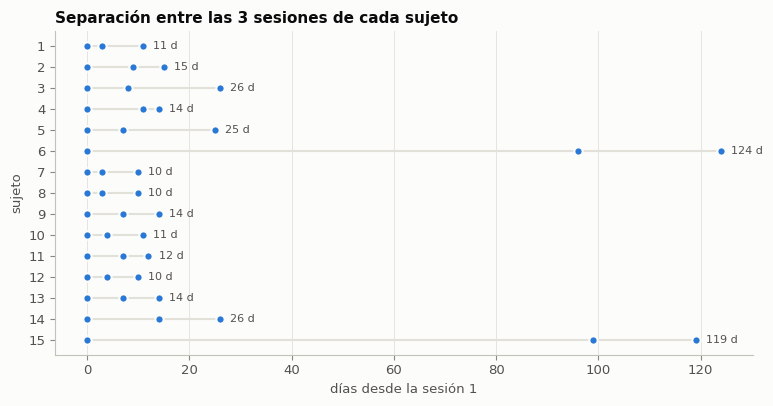

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.2))
for s in sorted(fechas):
    dias = [(x - fechas[s][0]).days for x in fechas[s]]
    ax.plot(dias, [s] * 3, color=GRID, lw=1.5, zorder=1)
    ax.scatter(dias, [s] * 3, s=36, color="#2a78d6", edgecolor=SUP, lw=1.5, zorder=2)
    ax.text(dias[-1] + 2, s, f"{dias[-1]} d", va="center", fontsize=8, color=TINTA2)
ax.set_yticks(range(1, 16))
ax.invert_yaxis()
ax.set_xlabel("días desde la sesión 1")
ax.set_ylabel("sujeto")
ax.set_title("Separación entre las 3 sesiones de cada sujeto")
ax.grid(axis="y", visible=False)
guardar(fig, "01_fechas_sesiones")
plt.show()

### 1.2 Las 15 películas (trials)

Las etiquetas están en `label.mat` (`1` positiva, `0` neutra, `-1` negativa) y son **las mismas para todos los sujetos y sesiones**, porque el orden de los clips es fijo. `SEED_stimulation.xlsx` dice qué película es cada trial (allí `0` = triste, `1` = neutra, `2` = alegre, que coincide con la codificación 0/1/2 del TFG).

La duración de cada trial sale del número de ventanas de 1 s en las features.

In [5]:
def leer_xlsx(ruta):
    # Lee la primera hoja de un .xlsx sin openpyxl (un .xlsx es un zip de XML)
    z = zipfile.ZipFile(ruta)
    textos = []
    if "xl/sharedStrings.xml" in z.namelist():
        for si in re.findall(r"<si>(.*?)</si>", z.read("xl/sharedStrings.xml").decode("utf8"), re.S):
            textos.append("".join(re.findall(r"<t[^>]*>([^<]*)</t>", si)))
    filas = []
    hoja = z.read("xl/worksheets/sheet1.xml").decode("utf8")
    for fila in re.findall(r"<row[^>]*>(.*?)</row>", hoja, re.S):
        celdas = []
        for attrs, cuerpo in re.findall(r"<c ([^>]*?)(?:/>|>(.*?)</c>)", fila, re.S):
            v = re.search(r"<v>([^<]*)</v>", cuerpo or "")
            v = v.group(1) if v else ""
            celdas.append(textos[int(v)] if ('t="s"' in attrs and v) else v)
        if any(celdas):
            filas.append(celdas)
    return filas

estim = leer_xlsx(SEED_DIR / "SEED_stimulation.xlsx")[1:16]
PELI  = [f[0].split("/")[0].replace("Aftershockk", "Aftershock").strip() for f in estim]
LABEL = d.load_labels()                                   # 0 neg, 1 neu, 2 pos
assert [int(f[1]) for f in estim] == LABEL.tolist(), "xlsx y label.mat no coinciden"

# Ventanas (= segundos) de cada trial en todas las sesiones
VENT = np.array([[dict((k, s) for k, s, _ in whosmat(fp))[f"de_LDS{t}"][1] for t in range(1, 16)]
                 for _, _, fp in sesiones])
print("¿Duración idéntica en las 45 sesiones?", bool((VENT == VENT[0]).all()))
DUR = VENT[0]

print(f"\n{'Trial':>5}  {'Emoción':<9} {'Duración':>8}  Película")
for t in range(15):
    print(f"{t + 1:>5}  {NOMBRE[LABEL[t]]:<9} {DUR[t]:>6} s  {PELI[t]}")
print(f"\nTotal por sesión: {DUR.sum()} s = {DUR.sum() / 60:.1f} min de EEG")

¿Duración idéntica en las 45 sesiones? True

Trial  Emoción   Duración  Película
    1  positiva     235 s  Lost in Thailand
    2  neutra       233 s  World Heritage in China
    3  negativa     206 s  Aftershock
    4  negativa     238 s  Back to 1942
    5  neutra       185 s  World Heritage in China
    6  positiva     195 s  Lost in Thailand
    7  negativa     237 s  Back to 1942
    8  neutra       216 s  World Heritage in China
    9  positiva     265 s  Flirting Scholar
   10  positiva     237 s  Just Another Pandora's Box
   11  neutra       235 s  World Heritage in China
   12  negativa     233 s  Back to 1942
   13  neutra       235 s  World Heritage in China
   14  positiva     238 s  Just Another Pandora's Box
   15  negativa     206 s  Aftershock

Total por sesión: 3394 s = 56.6 min de EEG


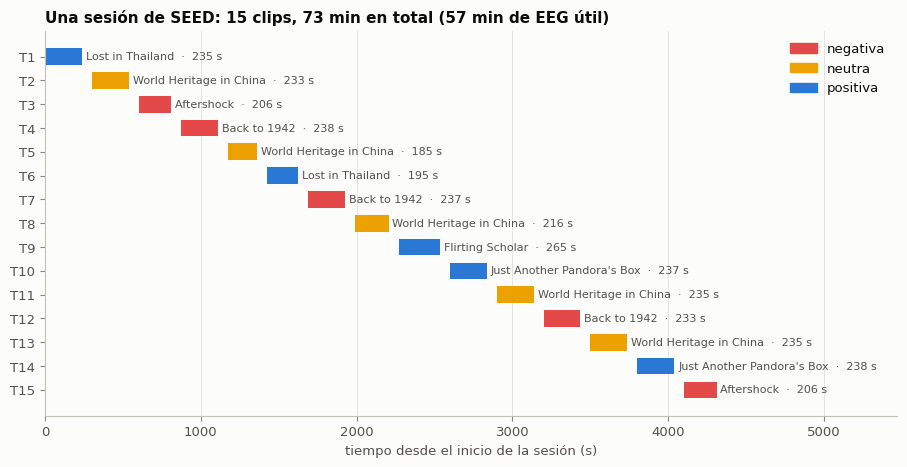

In [6]:
# Linea temporal de una sesion: aviso 5 s + clip + autoevaluacion 45 s + descanso 15 s
fig, ax = plt.subplots(figsize=(11, 5))
t0 = 0
for t in range(15):
    t0 += 5
    ax.barh(t + 1, DUR[t], left=t0, height=0.7, color=COLOR[LABEL[t]])
    ax.text(t0 + DUR[t] + 25, t + 1, f"{PELI[t]}  ·  {DUR[t]} s", va="center", fontsize=8, color=TINTA2)
    t0 += DUR[t] + 45 + 15
ax.set_yticks(range(1, 16))
ax.set_yticklabels([f"T{t}" for t in range(1, 16)])
ax.invert_yaxis()
ax.set_xlim(0, t0 + 1100)
ax.set_xlabel("tiempo desde el inicio de la sesión (s)")
ax.set_title(f"Una sesión de SEED: 15 clips, {t0 / 60:.0f} min en total ({DUR.sum() / 60:.0f} min de EEG útil)")
ax.grid(axis="y", visible=False)
leyenda_clases(ax, loc="upper right", ncol=1)
guardar(fig, "02_linea_temporal_sesion")
plt.show()

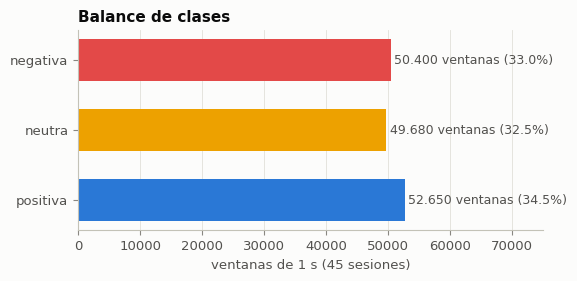

Total: 152.730 ventanas = 15 sujetos × 3 sesiones × 3394 s


In [7]:
por_clase = {c: int(DUR[LABEL == c].sum()) for c in CLASES}
fig, ax = plt.subplots(figsize=(6, 2.6))
for i, c in enumerate(CLASES):
    n = por_clase[c] * 45
    ax.barh(i, n, color=COLOR[c], height=0.6)
    ax.text(n + 600, i, f"{n:,} ventanas ({n / (DUR.sum() * 45):.1%})".replace(",", "."),
            va="center", fontsize=9, color=TINTA2)
ax.set_yticks(range(3))
ax.set_yticklabels([NOMBRE[c] for c in CLASES])
ax.invert_yaxis()
ax.set_xlim(0, 75000)
ax.set_xlabel("ventanas de 1 s (45 sesiones)")
ax.set_title("Balance de clases")
ax.grid(axis="y", visible=False)
guardar(fig, "03_balance_clases")
plt.show()
print(f"Total: {DUR.sum() * 45:,} ventanas = 15 sujetos × 3 sesiones × {DUR.sum()} s".replace(",", "."))

**Qué hay que quedarse de esta sección**

- **15 sujetos × 3 sesiones × 15 trials = 675 trials.** Cada sesión tiene 3394 s de EEG útil, así que hay **152 730 ventanas de 1 s** en total.
- **Las clases están casi equilibradas** (32.5-34.5 %). Por eso accuracy y F1 macro salen parecidas, y el azar está en torno al 34 %.
- **Los clips son idénticos para todos.** Duran entre 185 y 265 s, y cada trial dura exactamente lo mismo en las 45 sesiones.
- **Solo hay 6 películas distintas.** Los 5 neutros son fragmentos del mismo documental (*World Heritage in China*), los positivos son comedias y los negativos, dramas sobre catástrofes (el terremoto de Tangshan, la hambruna de 1942). La emoción va unida al tipo de película, así que un modelo puede aprender en parte el tipo de contenido (por ejemplo, reírse con una comedia) además del estado emocional.
- **Las etiquetas son de la película, no de lo que sintió cada persona en cada segundo.** Todas las ventanas de un clip llevan la misma etiqueta.
- **Las sesiones de un sujeto están separadas entre 1 y 4 semanas**, salvo en los sujetos 6 y 15, con unos 3-4 meses entre la 1.ª y la 2.ª.
- **En el experimento 01 (trials 1-9 de train, 10-15 de test) algunas películas están a ambos lados.** *Back to 1942* sale en T4 y T7 (train) y en T12 (test); *Aftershock*, en T3 (train) y en T15 (test). Otras solo están en test, como *Just Another Pandora's Box* (T10 y T14).

## 2. Los 62 electrodos y los 4 canales del TFG

El orden oficial de los canales está en `channel-order.xlsx`, y sus posiciones en la cabeza en `channel_62_pos.locs` (formato de EEGLAB: ángulo y radio). La fila *i* de cada matriz de SEED es el canal *i* de esta lista.

In [8]:
CANALES = [f[0] for f in leer_xlsx(SEED_DIR / "channel-order.xlsx")]
locs = [l.split() for l in (ROOT / "SEED" / "channel_62_pos.locs").read_text().splitlines() if l.strip()]
ang = np.deg2rad([float(l[1]) for l in locs])
rad = np.array([float(l[2]) for l in locs])
POS = np.c_[rad * np.sin(ang), rad * np.cos(ang)]          # x: izquierda-derecha, y: atrás-delante
assert [l[3].upper() for l in locs] == CANALES

print(len(CANALES), "canales")
for i in CH4:
    print(f"  índice {i:>2} -> {CANALES[i]}")
assert [CANALES[i] for i in CH4] == cfg.CHANNEL_NAMES

62 canales
  índice 14 -> FT7
  índice 22 -> FT8
  índice 23 -> T7
  índice 31 -> T8


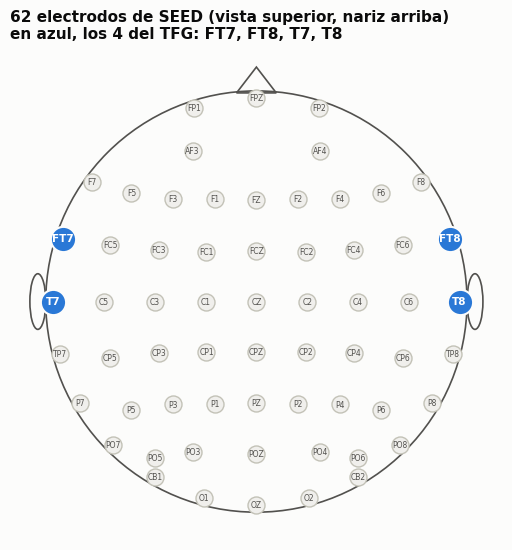

In [9]:
def cabeza(ax, r=0.53):
    ax.add_patch(Circle((0, 0), r, fill=False, ec=TINTA2, lw=1.2))
    ax.add_patch(Polygon([[-0.05, r - 0.005], [0, r + 0.06], [0.05, r - 0.005]], fill=False, ec=TINTA2, lw=1.2))
    for sx in (-1, 1):
        ax.add_patch(Ellipse((sx * (r + 0.02), 0), 0.04, 0.14, fill=False, ec=TINTA2, lw=1.2))
    ax.set_xlim(-0.62, 0.62); ax.set_ylim(-0.6, 0.64)
    ax.set_aspect("equal"); ax.axis("off")

fig, ax = plt.subplots(figsize=(6.4, 6.4))
cabeza(ax)
otros = [i for i in range(62) if i not in CH4]
ax.scatter(*POS[otros].T, s=150, color="#f0efec", edgecolor="#c3c2b7", zorder=2)
ax.scatter(*POS[CH4].T, s=330, color="#2a78d6", edgecolor=SUP, lw=1.5, zorder=3)
for i in range(62):
    ax.text(*POS[i], CANALES[i], ha="center", va="center", zorder=4,
            fontsize=7.5 if i in CH4 else 5.5, color="white" if i in CH4 else TINTA2,
            fontweight="bold" if i in CH4 else "normal")
ax.set_title("62 electrodos de SEED (vista superior, nariz arriba)\nen azul, los 4 del TFG: FT7, FT8, T7, T8")
guardar(fig, "04_electrodos")
plt.show()

def topomap(ax, valores, vmin, vmax, cmap, marcar=CH4):
    # Interpola 62 valores sobre la cabeza (se usa en las secciones 3, 6 y 7)
    g = np.linspace(-0.55, 0.55, 150)
    GX, GY = np.meshgrid(g, g)
    Zi = griddata(POS, valores, (GX, GY), method="cubic")
    Zi = np.where(np.isnan(Zi), griddata(POS, valores, (GX, GY), method="nearest"), Zi)
    Zi[GX ** 2 + GY ** 2 > 0.53 ** 2] = np.nan
    im = ax.imshow(Zi, extent=(-0.55, 0.55, -0.55, 0.55), origin="lower", cmap=cmap,
                   vmin=vmin, vmax=vmax, interpolation="bilinear")
    ax.contour(GX, GY, Zi, levels=6, colors=TINTA, linewidths=0.3, alpha=0.4)
    cabeza(ax)
    ax.scatter(*POS.T, s=2, color=TINTA2, zorder=3)
    ax.scatter(*POS[marcar].T, s=26, facecolor="none", edgecolor=TINTA, lw=1.2, zorder=4)
    return im

FT7/T7 están en el lóbulo temporal izquierdo (sobre la oreja) y FT8/T8 en el derecho. Zheng & Lu (2015) vieron que esa zona temporal lateral es la que más información da sobre la emoción, y por eso un perfil de solo 4 canales funciona casi como los 62.

> **Aviso sobre `notebooks/explorar_canales2.py`.** La lista de canales escrita a mano en ese script no coincide con `channel-order.xlsx` a partir del índice 24 (pone `CP5, CP3...` donde van `C5, C3...`, y añade `TP9`, `TP10`, `M1`, `M2`, que SEED no tiene). Los 4 índices que se usan (14, 22, 23, 31) **sí son correctos**, como comprueba la celda de arriba con la lista oficial; solo es un aviso por si se reutiliza esa lista.

## 3. La señal de EEG

`Preprocessed_EEG` tiene, para cada sesión, 15 matrices `(62 canales, muestras)` a 200 Hz, una por clip. Las claves del `.mat` llevan las iniciales del sujeto (`djc_eeg1`, `jl_eeg1`...), así que se buscan por el sufijo `_eeg<t>`.

Se carga primero la sesión 1 del sujeto 1.

In [10]:
def cargar_eeg(fp):
    # Devuelve la lista de los 15 trials (62, muestras) de una sesion, en orden
    m = loadmat(fp)
    claves = {int(re.search(r"_eeg(\d+)$", k).group(1)): k for k in m if re.search(r"_eeg\d+$", k)}
    return [m[claves[t]] for t in range(1, 16)]

fp_s1 = PRE_DIR / Path(sesiones[0][2]).name
eeg = cargar_eeg(fp_s1)
print("Fichero:", fp_s1.name)
for t in range(3):
    print(f"  trial {t + 1}: {eeg[t].shape} -> {eeg[t].shape[1] / FS:.1f} s   (ventanas en las features: {DUR[t]})")
todo = np.concatenate(eeg, axis=1)
print(f"\nAmplitud (se asume µV): mediana |x| = {np.median(np.abs(todo)):.1f}, "
      f"percentil 1-99 = [{np.percentile(todo, 1):.0f}, {np.percentile(todo, 99):.0f}], "
      f"máx |x| = {np.abs(todo).max():.0f}")

Fichero: 1_20131027.mat
  trial 1: (62, 47001) -> 235.0 s   (ventanas en las features: 235)
  trial 2: (62, 46601) -> 233.0 s   (ventanas en las features: 233)
  trial 3: (62, 41201) -> 206.0 s   (ventanas en las features: 206)



Amplitud (se asume µV): mediana |x| = 10.7, percentil 1-99 = [-1896, 232], máx |x| = 14641


### 3.1 Cómo se ve la señal

10 segundos de los 4 canales del TFG durante un clip positivo, uno neutro y uno negativo del mismo sujeto y sesión (misma escala vertical en los tres).

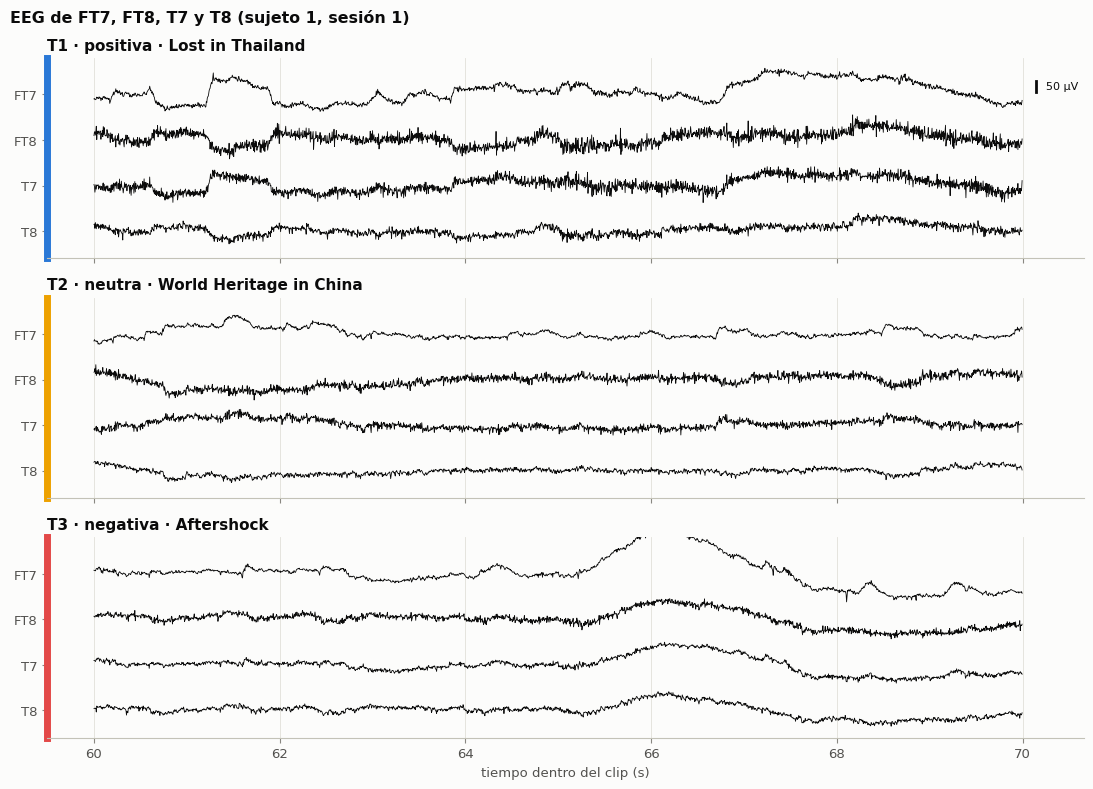

In [11]:
def trazas(ax, x, nombres, sep, t0=0.0):
    for j in range(len(x)):
        ax.plot(t0 + np.arange(x.shape[1]) / FS, x[j] - j * sep, color=TINTA, lw=0.6)
    ax.set_yticks([-j * sep for j in range(len(x))])
    ax.set_yticklabels(nombres)
    ax.grid(axis="y", visible=False)

ejemplo = {2: 0, 1: 1, 0: 2}           # clase -> trial (T1 positiva, T2 neutra, T3 negativa)
seg = slice(60 * FS, 70 * FS)          # segundos 60-70 del clip
sep = 6 * np.median([eeg[t][CH4, seg].std() for t in ejemplo.values()])

fig, axs = plt.subplots(3, 1, figsize=(11, 8), sharex=True)
for ax, c in zip(axs, [2, 1, 0]):
    t = ejemplo[c]
    trazas(ax, eeg[t][CH4, seg], cfg.CHANNEL_NAMES, sep, t0=60)
    ax.spines["left"].set_color(COLOR[c]); ax.spines["left"].set_linewidth(5)
    ax.set_title(f"T{t + 1} · {NOMBRE[c]} · {PELI[t]}")
    ax.set_ylim(-3.6 * sep, 0.8 * sep)
axs[-1].set_xlabel("tiempo dentro del clip (s)")
axs[0].plot([70.15, 70.15], [0.3 * sep, 0.3 * sep - 50], color=TINTA, lw=2, clip_on=False)
axs[0].text(70.25, 0.3 * sep - 25, "50 µV", va="center", fontsize=8)
fig.suptitle("EEG de FT7, FT8, T7 y T8 (sujeto 1, sesión 1)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "05_eeg_4canales_por_emocion")
plt.show()

**La emoción no se ve en la señal en bruto**: los tres clips se parecen. Lo que sí se aprecia:

- Ondas lentas grandes (derivas de decenas de µV) mezcladas con actividad rápida pequeña.
- En el clip positivo, FT8 y T7 tienen más actividad rápida, con picos finos. Ese tipo de actividad rápida es típico de la contracción muscular. En la sección 3.2 se ve que no es casualidad.
- En el clip negativo hay una onda lenta grande en FT7 hacia el segundo 66, seguramente un artefacto de movimiento de los ojos o del cuerpo.

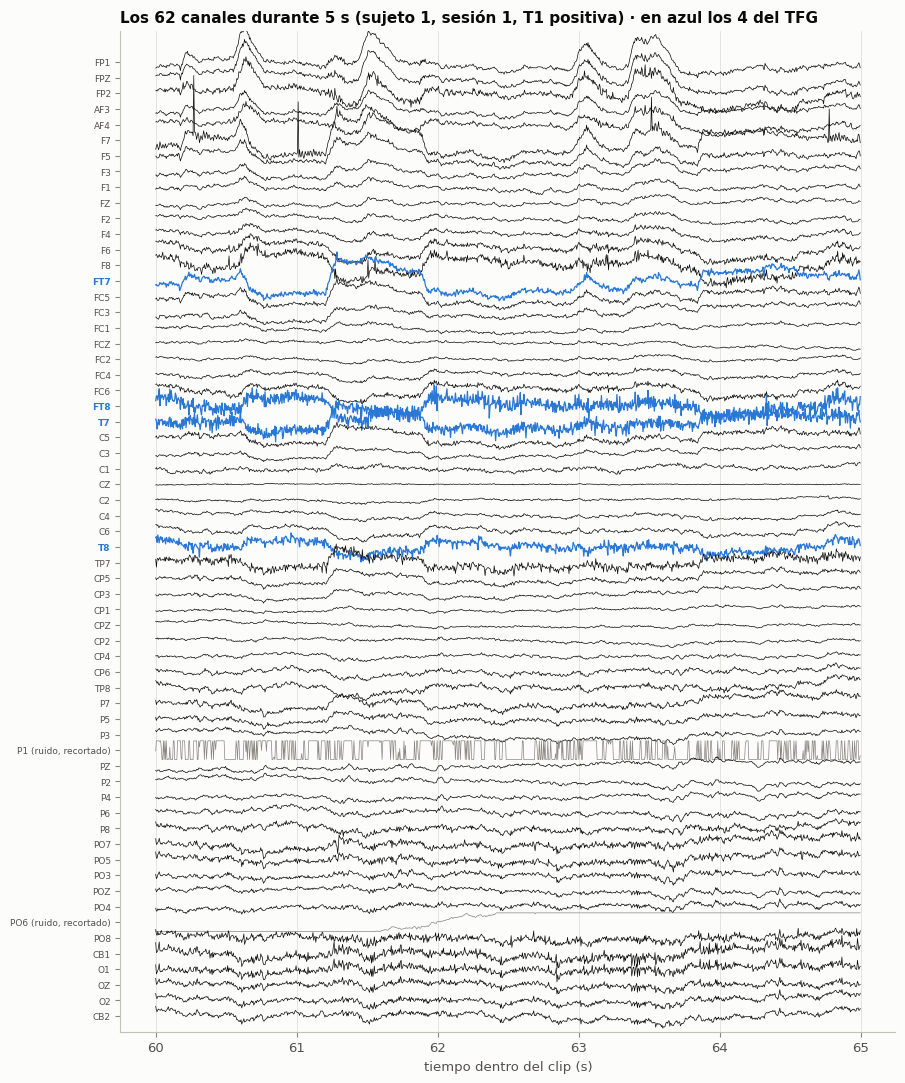

Desviación típica en estos 5 s (µV): {'P1': 380.9, 'PO6': 106.3} · mediana de los 62: 13.7 · CZ: 1.2


In [12]:
# Los 62 canales a la vez, 5 s del trial 1
seg5 = slice(60 * FS, 65 * FS)
x62 = eeg[0][:, seg5]
sd62 = x62.std(axis=1)
sep62 = 4 * np.median(sd62)
ruidosos = np.flatnonzero(sd62 > 5 * np.median(sd62))
fig, ax = plt.subplots(figsize=(10, 13))
for j in range(62):
    xj = x62[j] - x62[j].mean()
    if j in ruidosos:                      # se recorta solo para dibujarlo
        xj = np.clip(xj, -0.6 * sep62, 0.6 * sep62)
    ax.plot(60 + np.arange(x62.shape[1]) / FS, xj - j * sep62,
            color="#2a78d6" if j in CH4 else (MUTED if j in ruidosos else TINTA),
            lw=0.9 if j in CH4 else 0.5)
ax.set_yticks([-j * sep62 for j in range(62)])
ax.set_yticklabels([f"{c} (ruido, recortado)" if j in ruidosos else c for j, c in enumerate(CANALES)], fontsize=6.5)
for lbl, j in zip(ax.get_yticklabels(), range(62)):
    if j in CH4:
        lbl.set_color("#2a78d6"); lbl.set_fontweight("bold")
ax.set_ylim(-62 * sep62, 2 * sep62)
ax.grid(axis="y", visible=False)
ax.set_xlabel("tiempo dentro del clip (s)")
ax.set_title("Los 62 canales durante 5 s (sujeto 1, sesión 1, T1 positiva) · en azul los 4 del TFG")
guardar(fig, "06_eeg_62canales")
plt.show()
print("Desviación típica en estos 5 s (µV):", {CANALES[j]: round(float(sd62[j]), 1) for j in ruidosos},
      f"· mediana de los 62: {np.median(sd62):.1f} · CZ: {sd62[CANALES.index('CZ')]:.1f}")

- **Los canales frontales** (FP1, FPZ, FP2, AF3, AF4, F7) tienen picos lentos a la vez: son **parpadeos**, porque los ojos están justo debajo.
- **P1 y PO6 están rotos en esta sesión.** Su desviación típica en estos 5 s es de cientos de µV, frente a unos 14 µV de mediana (aquí se dibujan recortados). SEED no elimina ni corrige estos canales. Ver la sección 8.2.
- **CZ es casi plano** (≈ 1 µV), lo que hace pensar que es el electrodo de referencia o está junto a él.
- **Los canales vecinos se parecen mucho**: el EEG está muy correlacionado en el espacio. Por eso 62 canales no dan 62 veces más información que uno.

### 3.2 Espectro de potencia por emoción

Lo que importa para la emoción no es la forma de la onda sino **cuánta energía hay en cada banda de frecuencia**. El espectro de potencia (método de Welch, ventanas de 2 s) se calcula para cada trial y se promedia por emoción. Se usa la **sesión 1 de los 15 sujetos**.

Para comparar emociones sin que pesen las diferencias de amplitud entre personas, en el panel de la derecha a cada sujeto se le resta su propio espectro medio (media de las 3 emociones) antes de promediar.

In [13]:
f_w = None
PSD = np.zeros((15, 15, 62, 201))                 # sujeto, trial, canal, frecuencia
for i, (s, k, fp) in enumerate([x for x in sesiones if x[1] == 1]):
    ee = eeg if s == 1 else cargar_eeg(PRE_DIR / Path(fp).name)
    for t in range(15):
        f_w, PSD[i, t] = welch(ee[t], fs=FS, nperseg=2 * FS)
print("PSD calculada para la sesión 1 de los 15 sujetos:", PSD.shape)
dB =10 * np.log10(PSD[..., CH4, :].mean(axis=2))         # media de los 4 canales -> (15, 15, 201)
# por sujeto y clase
dB_c = np.stack([dB[:, LABEL == c].mean(axis=1) for c in CLASES], axis=1)   # (15 suj, 3, f)
rel = dB_c - dB_c.mean(axis=1, keepdims=True)

PSD calculada para la sesión 1 de los 15 sujetos: (15, 15, 62, 201)


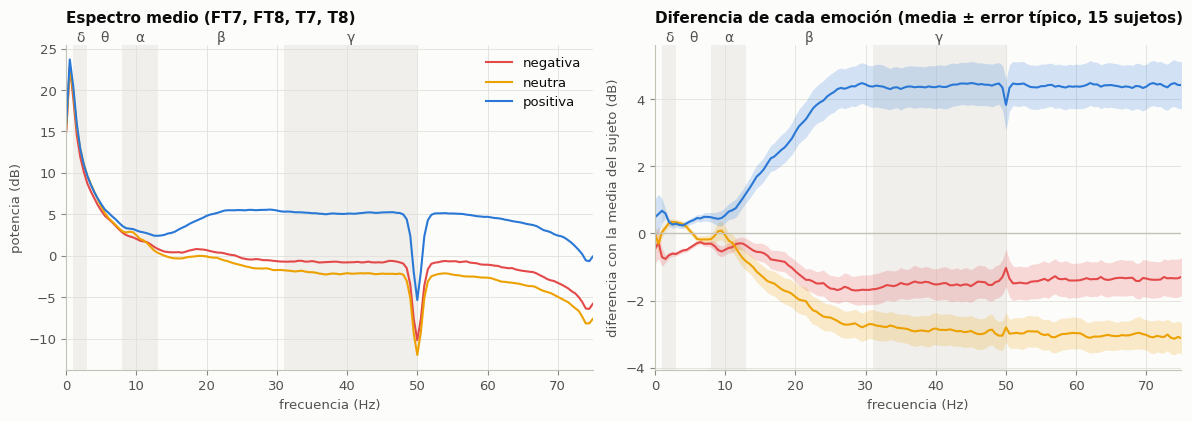

In [14]:
GRIEGA = {"delta": "δ", "theta": "θ", "alpha": "α", "beta": "β", "gamma": "γ"}
def bandas_fondo(ax, etiquetas=True, y=None):
    for j, (b, (lo, hi)) in enumerate(BANDAS.items()):
        if j % 2 == 0:
            ax.axvspan(lo, hi, color="#f0efec", lw=0, zorder=0)
        if etiquetas:
            ax.text((lo + hi) / 2, y, GRIEGA[b], ha="center", va="bottom", fontsize=10, color=TINTA2,
                    transform=ax.get_xaxis_transform())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.3))
m = f_w <= 75
for c in CLASES:
    axs[0].plot(f_w[m], dB_c[:, c, m].mean(0), color=COLOR[c], label=NOMBRE[c])
    mu, se = rel[:, c, m].mean(0), rel[:, c, m].std(0) / np.sqrt(15)
    axs[1].fill_between(f_w[m], mu - se, mu + se, color=COLOR[c], alpha=0.2, lw=0)
    axs[1].plot(f_w[m], mu, color=COLOR[c], label=NOMBRE[c])
axs[1].axhline(0, color="#c3c2b7", lw=1)
for ax in axs:
    bandas_fondo(ax, y=1.0)
    ax.set_xlabel("frecuencia (Hz)")
    ax.set_xlim(0, 75)
axs[0].set_ylabel("potencia (dB)")
axs[1].set_ylabel("diferencia con la media del sujeto (dB)")
axs[0].set_title("Espectro medio (FT7, FT8, T7, T8)", pad=16)
axs[1].set_title("Diferencia de cada emoción (media ± error típico, 15 sujetos)", pad=16)
axs[0].legend(loc="upper right")
fig.tight_layout()
guardar(fig, "07_espectro_por_emocion")
plt.show()

Aquí aparece la **diferencia principal entre emociones**:

- Por debajo de unos 12 Hz, las tres emociones tienen prácticamente el mismo espectro.
- Desde unos 15 Hz, los clips **positivos** tienen unos **4 dB más** de potencia que la media de cada sujeto, es decir, unas 2.5 veces más potencia. La diferencia se mantiene plana hasta 75 Hz.
- Neutros y negativos quedan por debajo de la media, y los neutros son los más bajos en beta y gamma.
- La caída a 50 Hz es el filtro de la red eléctrica (en China, 50 Hz).

Esto coincide con Zheng & Lu (2015), que encontraron que beta y gamma son las bandas más discriminativas.

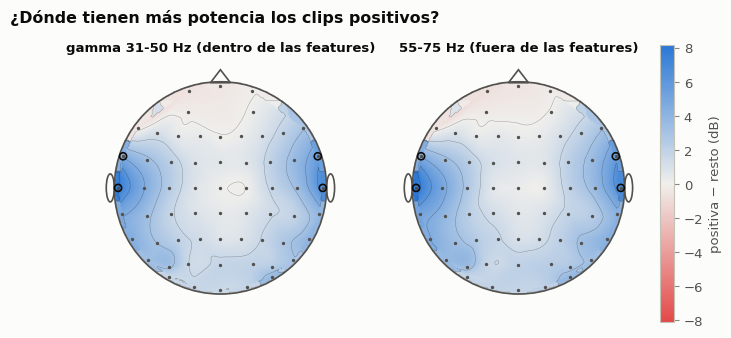

In [15]:
# Positiva - (media de neutra y negativa), en dB, por electrodo: gamma frente a 55-75 Hz
dB62 = 10 * np.log10(PSD)                                              # (suj, trial, canal, f)
pos_menos = (dB62[:, LABEL == 2].mean(1) - dB62[:, LABEL != 2].mean(1)).mean(0)   # (canal, f)
rangos = {"gamma 31-50 Hz (dentro de las features)": (31, 50), "55-75 Hz (fuera de las features)": (55, 75)}
fig, axs = plt.subplots(1, 2, figsize=(7.5, 3.6))
lim_hf = max(np.abs(pos_menos[:, (f_w >= lo) & (f_w <= hi)].mean(1)).max() for lo, hi in rangos.values())
for ax, (titulo, (lo, hi)) in zip(axs, rangos.items()):
    v = pos_menos[:, (f_w >= lo) & (f_w <= hi)].mean(1)
    im = topomap(ax, v, -lim_hf, lim_hf, DIV)
    ax.set_title(titulo, loc="center", fontsize=9.5)
cb = fig.colorbar(im, ax=axs, fraction=0.03, pad=0.03); cb.set_label("positiva − resto (dB)")
fig.suptitle("¿Dónde tienen más potencia los clips positivos?", x=0.01, ha="left", fontweight="bold")
guardar(fig, "07b_topomapa_alta_frecuencia")
plt.show()

**Aviso importante para la memoria: posible contaminación muscular (EMG).** La ventaja de los clips positivos tiene dos rasgos típicos de la actividad muscular, más que de la cerebral (Goncharova et al., 2003):

1. **Es plana desde unos 25 Hz hasta 75 Hz**, más allá de la banda gamma. La potencia del EEG cerebral, en cambio, baja al subir la frecuencia.
2. **Se concentra en los bordes laterales de la cabeza** (FT7, T7, FT8, T8), justo encima del músculo temporal. Además, el mapa a 55-75 Hz, fuera de las bandas de las features, es casi igual que el de gamma.

Los clips positivos son comedias, y reír o sonreír contrae los músculos de la cara y de la mandíbula, cuya actividad captan los electrodos temporales. **Es una hipótesis plausible, no algo que este análisis demuestre**: también hay explicaciones neuronales, y Zheng & Lu lo interpretan como actividad cerebral. Aun así, conviene mencionarla en las limitaciones. Parte de lo que usan los modelos para reconocer "positiva" podría ser la expresión facial y no solo la emoción en el cerebro.

Para un dispositivo con 4 canales temporales esto no es necesariamente malo, porque la señal existe y es útil. Pero cambia cómo se interpreta el resultado.

### 3.3 Espectrograma de una sesión completa

El espectrograma muestra la potencia de cada frecuencia segundo a segundo. Aquí se encadenan los 15 clips de la sesión 1 del sujeto 1 (canal T8). Cada fila de frecuencia se normaliza (z-score a lo largo de la sesión) para ver **cuándo** sube o baja cada frecuencia respecto a su nivel típico: azul = más potencia de lo normal, rojo = menos.

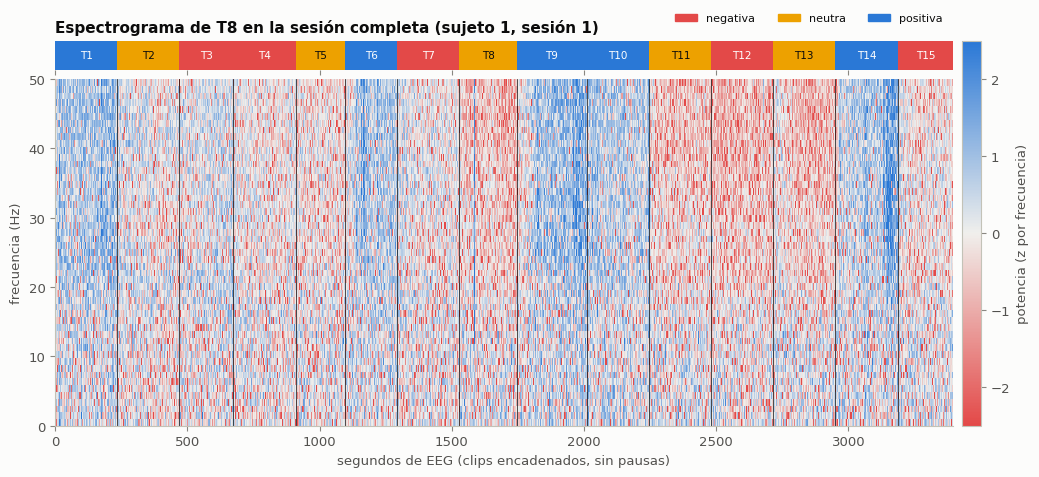

In [16]:
filas, y_seg = [], []
for t in range(15):
    f_s, _, S = spectrogram(eeg[t][cfg.CHANNEL_INDICES[3]], fs=FS, nperseg=FS, noverlap=0)
    filas.append(10 * np.log10(S + 1e-12)); y_seg += [LABEL[t]] * S.shape[1]
S = np.concatenate(filas, axis=1)
S = S[f_s <= 50]
S = (S - S.mean(1, keepdims=True)) / S.std(1, keepdims=True)
y_seg = np.array(y_seg)

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 5), sharex=True, gridspec_kw={"height_ratios": [1, 12], "hspace": 0.05})
fondo_clases(a0, y_seg, alpha=1)
a0.set_yticks([]); a0.grid(False); a0.spines[:].set_visible(False)
cambios = np.r_[0, np.flatnonzero(np.diff(np.repeat(np.arange(15), DUR))) + 1]
for t, x0 in enumerate(cambios):
    a0.text(x0 + DUR[t] / 2, 0.5, f"T{t + 1}", ha="center", va="center", fontsize=7.5,
            color=TINTA if LABEL[t] == 1 else "white")
a0.set_title("Espectrograma de T8 en la sesión completa (sujeto 1, sesión 1)", pad=6)
im = a1.imshow(S, aspect="auto", origin="lower", cmap=DIV, vmin=-2.5, vmax=2.5,
               extent=(0, S.shape[1], f_s[0], f_s[f_s <= 50][-1]), interpolation="nearest")
for x0 in cambios[1:]:
    a1.axvline(x0, color=TINTA, lw=0.5)
a1.set_ylabel("frecuencia (Hz)"); a1.set_xlabel("segundos de EEG (clips encadenados, sin pausas)")
a1.grid(False)
cb = fig.colorbar(im, ax=[a0, a1], pad=0.01, fraction=0.025)
cb.set_label("potencia (z por frecuencia)")
leyenda_clases(a0, loc="lower right", bbox_to_anchor=(1.0, 1.25), ncol=3, fontsize=8)
guardar(fig, "08_espectrograma_sesion")
plt.show()

- **Las franjas verticales azules coinciden con los clips positivos** (T1, T6, T9, T10, T14), sobre todo por encima de unos 15 Hz. Los neutros y negativos se ven más rojos: menos potencia rápida.
- **La potencia también cambia dentro de un mismo clip.** Hay momentos concretos con más potencia (por ejemplo, al final de T9 y de T14), que probablemente son las escenas más divertidas.
- **Por debajo de unos 10 Hz el patrón es mucho más débil.**

## 4. De la señal a la feature: entropía diferencial (DE)

Las features de `ExtractedFeatures_1s` se calculan así para cada canal:

1. Se divide la señal en **ventanas de 1 s** sin solapamiento (200 muestras). Por eso un clip de 235 s da 235 ventanas.
2. En cada ventana se mide la energía en las **5 bandas**: delta (1-3 Hz), theta (4-7), alpha (8-13), beta (14-30) y gamma (31-50).
3. **PSD** (*power spectral density*) es esa potencia; **DE** (*differential entropy*) es su logaritmo. Para una señal gaussiana filtrada en una banda, con varianza σ²:

$$DE = \tfrac{1}{2}\log\left(2\pi e\,\sigma^2\right)$$

   Es decir, DE ≈ log(potencia de la banda). El logaritmo comprime las diferencias enormes de potencia entre bandas y personas, y por eso funciona mejor que la PSD (Duan et al., 2013).
4. Las features de cada ventana se **suavizan a lo largo del trial**: `movingAve` (media móvil) o `LDS` (*linear dynamic system*, un suavizado tipo Kalman que usa **todo el trial**, pasado y futuro).

Cada fichero trae 12 tipos de features (todas `(canales, ventanas, 5 bandas)`):

In [17]:
w = whosmat(sesiones[0][2])
tipos = sorted({re.sub(r"\d+$", "", k) for k, _, _ in w})
forma = {re.sub(r"\d+$", "", k): s for k, s, _ in w if k.endswith("1") and not k.endswith("11")}
desc = {"de": "entropía diferencial por canal", "psd": "potencia por canal",
        "dasm": "DE izquierda − derecha (27 pares)", "rasm": "DE izquierda / derecha (27 pares)",
        "asm": "dasm y rasm juntas (54)", "dcau": "DE delante − detrás (23 pares)"}
for t in tipos:
    print(f"{t:<16} {str(forma[t]):<15} {desc[t.split('_')[0]]}")

asm_LDS          (54, 235, 5)    dasm y rasm juntas (54)
asm_movingAve    (54, 235, 5)    dasm y rasm juntas (54)
dasm_LDS         (27, 235, 5)    DE izquierda − derecha (27 pares)
dasm_movingAve   (27, 235, 5)    DE izquierda − derecha (27 pares)
dcau_LDS         (23, 235, 5)    DE delante − detrás (23 pares)
dcau_movingAve   (23, 235, 5)    DE delante − detrás (23 pares)
de_LDS           (62, 235, 5)    entropía diferencial por canal
de_movingAve     (62, 235, 5)    entropía diferencial por canal
psd_LDS          (62, 235, 5)    potencia por canal
psd_movingAve    (62, 235, 5)    potencia por canal
rasm_LDS         (27, 235, 5)    DE izquierda / derecha (27 pares)
rasm_movingAve   (27, 235, 5)    DE izquierda / derecha (27 pares)


### 4.1 Una ventana descompuesta en bandas

3 segundos de T8 filtrados en cada banda. Cada recuadro es una ventana de 1 s, y el número es su DE calculada con la fórmula de arriba. Las bandas lentas tienen mucha más amplitud (y DE más alta) que las rápidas.

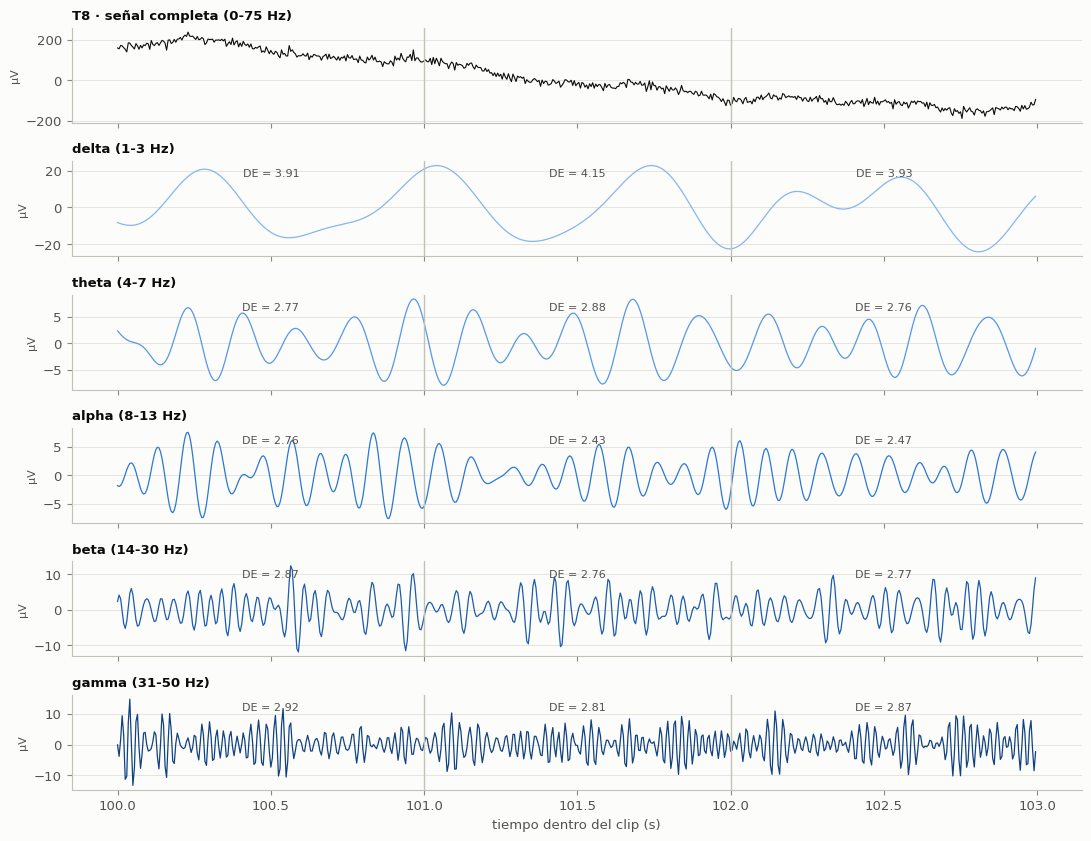

In [18]:
def filtrar(x, banda):
    sos = butter(4, banda, btype="band", fs=FS, output="sos")
    return sosfiltfilt(sos, x, axis=-1)

def de_manual(x, banda):
    y = filtrar(x, banda)
    n = y.shape[-1] // FS
    v = y[..., :n * FS].reshape(*y.shape[:-1], n, FS).var(axis=-1)
    return 0.5 * np.log(2 * np.pi * np.e * v)

x_t8 = eeg[0][cfg.CHANNEL_INDICES[3]]
ini, fin = 100 * FS, 103 * FS
tt = np.arange(ini, fin) / FS
fig, axs = plt.subplots(6, 1, figsize=(11, 8.5), sharex=True)
axs[0].plot(tt, x_t8[ini:fin], color=TINTA, lw=0.8)
axs[0].set_title("T8 · señal completa (0-75 Hz)", fontsize=9.5)
for j, (b, banda) in enumerate(BANDAS.items()):
    y = filtrar(x_t8, banda)[ini:fin]
    de = de_manual(x_t8, banda)[100:103]
    ax = axs[j + 1]
    ax.plot(tt, y, color=COLOR_BANDA[j], lw=0.9)
    ax.set_title(f"{b} ({banda[0]}-{banda[1]} Hz)", fontsize=9.5)
    for k in range(3):
        ax.text(100.5 + k, 0.92, f"DE = {de[k]:.2f}", transform=ax.get_xaxis_transform(),
                ha="center", va="top", fontsize=8, color=TINTA2)
for ax in axs:
    for k in (101, 102):
        ax.axvline(k, color="#c3c2b7", lw=1)
    ax.set_ylabel("µV", fontsize=8)
    ax.grid(axis="x", visible=False)
axs[-1].set_xlabel("tiempo dentro del clip (s)")
fig.tight_layout()
guardar(fig, "09_bandas_y_de")
plt.show()

### 4.2 ¿Coincide mi DE con la de SEED?

Se compara la DE calculada aquí (filtro Butterworth + fórmula) con `de_movingAve` del fichero oficial, para todos los canales y ventanas del trial 1. SEED la calcula con una STFT y otra escala, así que no se espera el mismo número, pero sí una **relación lineal** si ambas miden lo mismo.

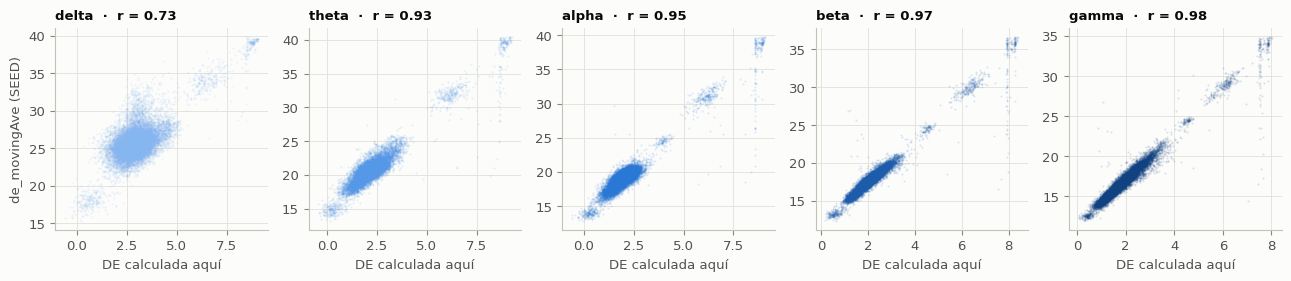

In [19]:
f_s1 = loadmat(sesiones[0][2])
fig, axs = plt.subplots(1, 5, figsize=(13, 2.9))
corr_de = {}
for j, (b, banda) in enumerate(BANDAS.items()):
    mio = de_manual(eeg[0], banda)                      # (62, 235)
    oficial = f_s1["de_movingAve1"][:, :, j]
    r = np.corrcoef(mio.ravel(), oficial.ravel())[0, 1]
    corr_de[b] = r
    axs[j].scatter(mio.ravel(), oficial.ravel(), s=2, alpha=0.15, color=COLOR_BANDA[j], lw=0)
    axs[j].set_title(f"{b}  ·  r = {r:.2f}", fontsize=9.5)
    axs[j].set_xlabel("DE calculada aquí")
axs[0].set_ylabel("de_movingAve (SEED)")
fig.tight_layout()
guardar(fig, "10_de_manual_vs_seed")
plt.show()

- **En theta, alpha, beta y gamma (r = 0.93-0.98) mi DE y la oficial están casi en línea recta.** La idea es la misma: el logaritmo de la potencia de la banda. Solo cambia la escala, porque SEED usa una STFT y otra normalización.
- **En delta la relación es peor (r = 0.73).** Una ventana de 1 s solo contiene 1-3 ciclos de delta, así que el resultado depende mucho del método de cálculo.
- **Los grupos de puntos alejados, arriba a la derecha, son los canales ruidosos P1 y PO6**, con una DE muy alta.

### 4.3 Suavizado: `movingAve` frente a `LDS`

La DE ventana a ventana es ruidosa. SEED la suaviza a lo largo del trial. Abajo, la DE gamma de T8 en el trial 1 sin suavizar (calculada aquí, reescalada a la escala de SEED con un ajuste lineal), con media móvil y con LDS.

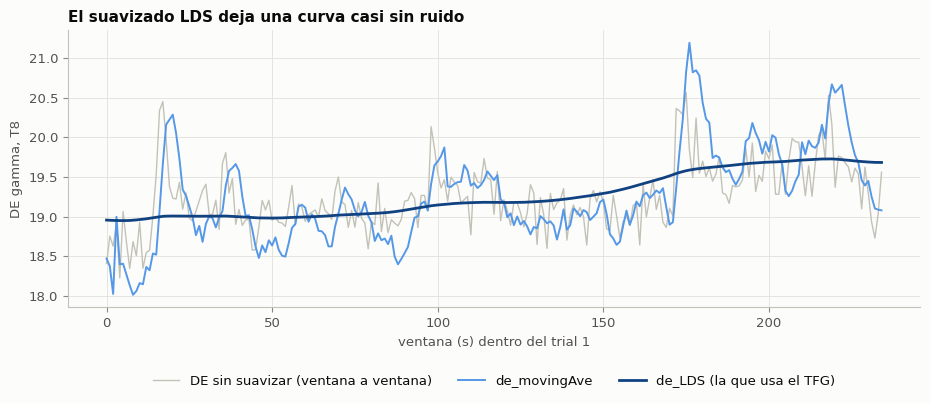

In [20]:
mio = de_manual(eeg[0][[cfg.CHANNEL_INDICES[3]]], BANDAS["gamma"])[0]
ma = f_s1["de_movingAve1"][cfg.CHANNEL_INDICES[3], :, 4]
lds = f_s1["de_LDS1"][cfg.CHANNEL_INDICES[3], :, 4]
a, b0 = np.polyfit(mio, ma, 1)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.plot(a * mio + b0, color="#c3c2b7", lw=1, label="DE sin suavizar (ventana a ventana)")
ax.plot(ma, color="#5598e7", lw=1.4, label="de_movingAve")
ax.plot(lds, color="#104281", lw=2, label="de_LDS (la que usa el TFG)")
ax.set_xlabel("ventana (s) dentro del trial 1")
ax.set_ylabel("DE gamma, T8")
ax.set_title("El suavizado LDS deja una curva casi sin ruido")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=3)
guardar(fig, "11_suavizado_lds")
plt.show()

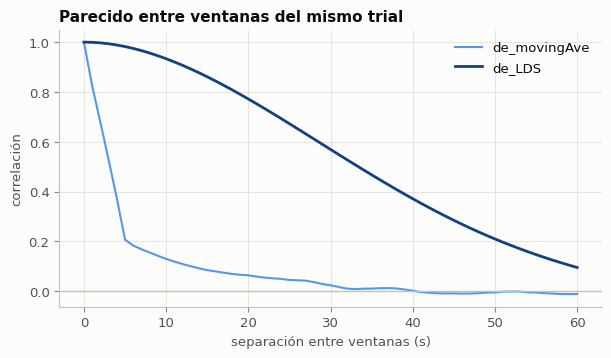

Correlación entre ventanas consecutivas: movingAve 0.8244 · LDS 0.9992
Correlación a 10 s: movingAve 0.130 · LDS 0.933


In [21]:
# Autocorrelacion de la feature en funcion del desfase entre ventanas
def autocorr(x, lags):
    x = x - x.mean()
    return np.array([1.0 if L == 0 else np.corrcoef(x[:-L], x[L:])[0, 1] for L in lags])

lags = np.arange(0, 61)
ac = {k: [] for k in ("de_movingAve", "de_LDS")}
for k in ac:
    for t in range(1, 16):
        A = f_s1[f"{k}{t}"]
        for ch in range(0, 62, 4):
            for bnd in range(5):
                ac[k].append(autocorr(A[ch, :, bnd], lags))
    ac[k] = np.mean(ac[k], axis=0)

fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(lags, ac["de_movingAve"], color="#5598e7", label="de_movingAve")
ax.plot(lags, ac["de_LDS"], color="#104281", lw=2, label="de_LDS")
ax.axhline(0, color="#c3c2b7", lw=1)
ax.set_xlabel("separación entre ventanas (s)")
ax.set_ylabel("correlación")
ax.set_title("Parecido entre ventanas del mismo trial")
ax.legend()
guardar(fig, "12_autocorrelacion")
plt.show()
print(f"Correlación entre ventanas consecutivas: movingAve {ac['de_movingAve'][1]:.4f} · LDS {ac['de_LDS'][1]:.4f}")
print(f"Correlación a 10 s: movingAve {ac['de_movingAve'][10]:.3f} · LDS {ac['de_LDS'][10]:.3f}")

- **`movingAve`**: la correlación cae en línea recta hasta unos 5 s y después casi desaparece. Es una media móvil de unas 5 ventanas.
- **`LDS`**: dos ventanas seguidas tienen correlación **0.999**, y a 10 s de distancia todavía 0.93. LDS suaviza con el trial entero, mirando al pasado y al futuro.

**Consecuencias para el TFG**

1. **Las ventanas de un trial no son muestras independientes.** Un trial de 235 s es más bien un solo dato con 235 copias casi iguales. Si las ventanas se reparten al azar entre train y test, el test contiene copias del train y sale una accuracy cercana al 100 % que es falsa. Es lo que pasó con `random_split` en `legacy/`. Por eso los splits se hacen por trial (exp. 01) o por sujeto (02-04).
2. **Hay muchas menos muestras efectivas de lo que parece**: 675 trials, no 152 730 ventanas.
3. **LDS mira al futuro, así que no se puede calcular igual en tiempo real** (limitación ya anotada en el README).

## 5. Las features `de_LDS` a lo largo de una sesión

Ahora se cargan las features de todo el dataset, igual que en los experimentos (`eeg_emotion.data.load_seed_features`, 62 canales): una fila por ventana de 1 s y 62 × 5 = 310 columnas (canal × banda).

In [22]:
X, meta = d.load_seed_features(channels=62)
X = X.astype(np.float32)
y, suj, ses, tri, tid = meta["y"], meta["subject"], meta["session"], meta["trial"], meta["trial_id"]
print("X:", X.shape, "  sujetos:", np.unique(suj).size, "  trials:", np.unique(tid).size)
col = lambda ch, b: ch * 5 + b                       # columna de (canal, banda)

X: (152730, 310)   sujetos: 15   trials: 675


### 5.1 Los 4 canales del TFG durante una sesión

DE gamma de FT7, FT8, T7 y T8 en las 3394 ventanas de la sesión 1 del sujeto 1. **El fondo indica la emoción del clip.** Aquí es donde mejor se "ve" la emoción a simple vista.

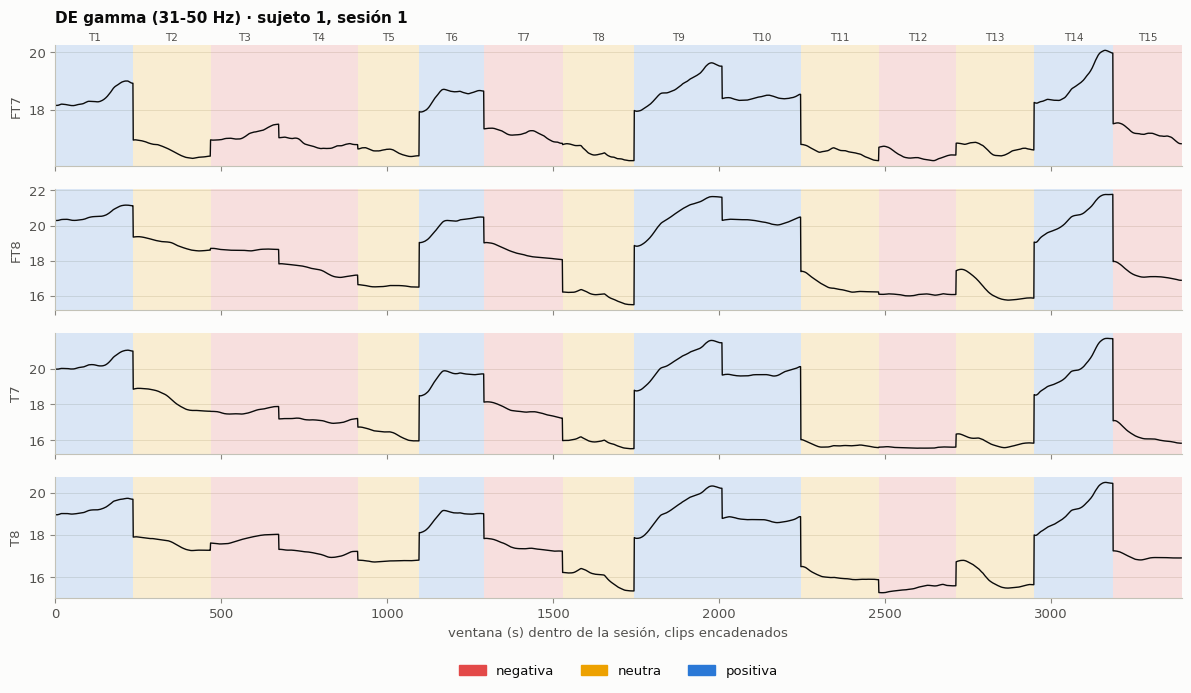

In [23]:
m11 = (suj == 1) & (ses == 1)
y11 = y[m11]
cambios = np.r_[0, np.flatnonzero(np.diff(tri[m11])) + 1]

def panel_sesion(axs, banda, titulo):
    for ax, ch, nombre in zip(axs, CH4, cfg.CHANNEL_NAMES):
        fondo_clases(ax, y11)
        ax.plot(X[m11, col(ch, banda)], color=TINTA, lw=1)
        ax.set_ylabel(nombre)
        ax.grid(axis="x", visible=False)
    for t, x0 in enumerate(cambios):
        axs[0].text(x0 + DUR[t] / 2, 1.02, f"T{t + 1}", transform=axs[0].get_xaxis_transform(),
                    ha="center", va="bottom", fontsize=7.5, color=TINTA2)
    axs[0].set_title(titulo, pad=16)
    axs[-1].set_xlabel("ventana (s) dentro de la sesión, clips encadenados")
    axs[-1].set_xlim(0, m11.sum())

fig, axs = plt.subplots(4, 1, figsize=(12, 7), sharex=True)
panel_sesion(axs, 4, "DE gamma (31-50 Hz) · sujeto 1, sesión 1")
leyenda_clases(axs[-1], loc="upper center", bbox_to_anchor=(0.5, -0.45), ncol=3)
fig.tight_layout()
guardar(fig, "13_sesion_gamma_4canales")
plt.show()

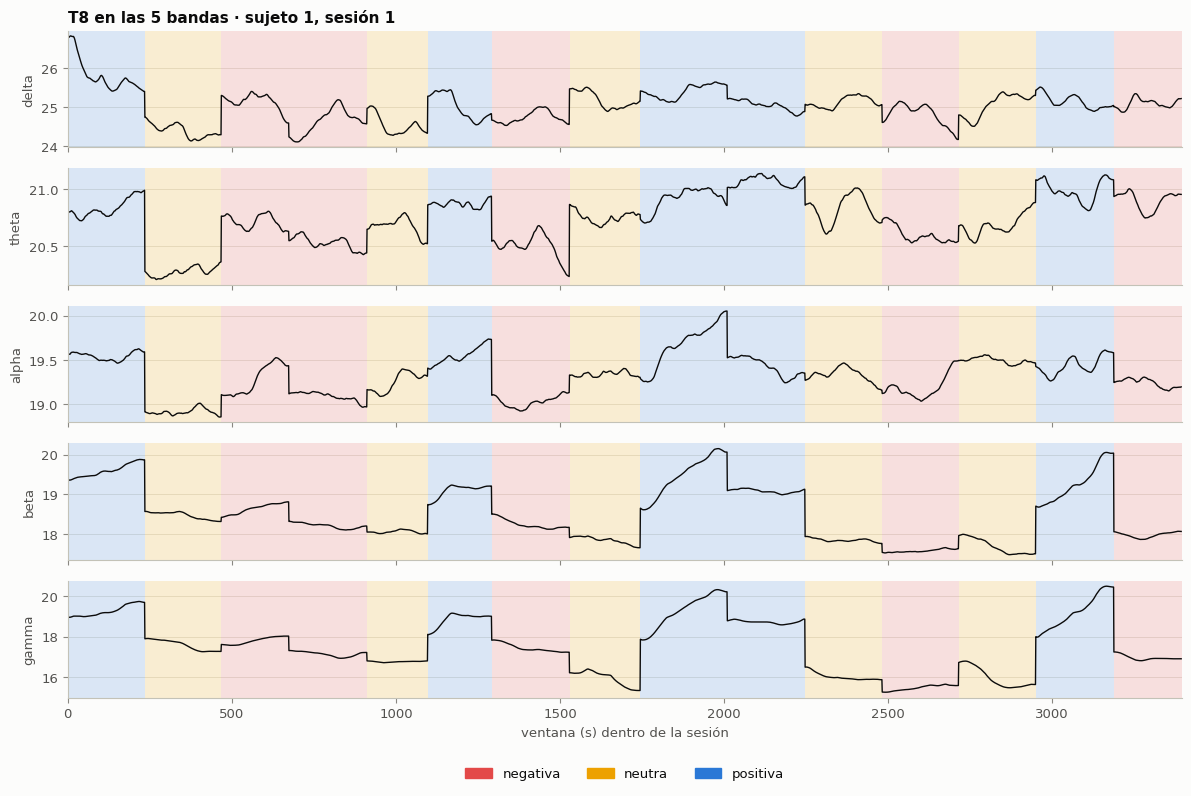

In [24]:
fig, axs = plt.subplots(5, 1, figsize=(12, 8), sharex=True)
for j, ax in enumerate(axs):
    fondo_clases(ax, y11)
    ax.plot(X[m11, col(cfg.CHANNEL_INDICES[3], j)], color=TINTA, lw=1)
    ax.set_ylabel(NB[j])
    ax.grid(axis="x", visible=False)
axs[0].set_title("T8 en las 5 bandas · sujeto 1, sesión 1")
axs[-1].set_xlabel("ventana (s) dentro de la sesión")
axs[-1].set_xlim(0, m11.sum())
leyenda_clases(axs[-1], loc="upper center", bbox_to_anchor=(0.5, -0.5), ncol=3)
fig.tight_layout()
guardar(fig, "14_sesion_t8_5bandas")
plt.show()

**En esta figura es donde mejor se ve la emoción**:

- **En gamma, los 4 canales suben en cuanto empieza un clip positivo** (fondo azul) y bajan al pasar a uno neutro o negativo. **Entre neutros y negativos casi no hay diferencia.**
- **Cada trial es casi un escalón.** El valor salta en el cambio de clip y dentro del clip varía despacio, porque el suavizado LDS se aplica a cada trial por separado.
- **En T9 y T14 (comedias), gamma sube hacia el final del clip.**
- En T8, **beta se comporta igual que gamma**. Theta y alpha cambian de un clip a otro sin un patrón claro por emoción en este sujeto, y delta casi no sigue a la emoción.

### 5.2 Las 310 features a la vez

Cada fila es una feature (agrupadas por banda; dentro de cada banda, los 62 canales en orden) y cada columna una ventana de 1 s. Cada fila está normalizada (z-score) dentro de la sesión: azul = valor por encima de su media, rojo = por debajo.

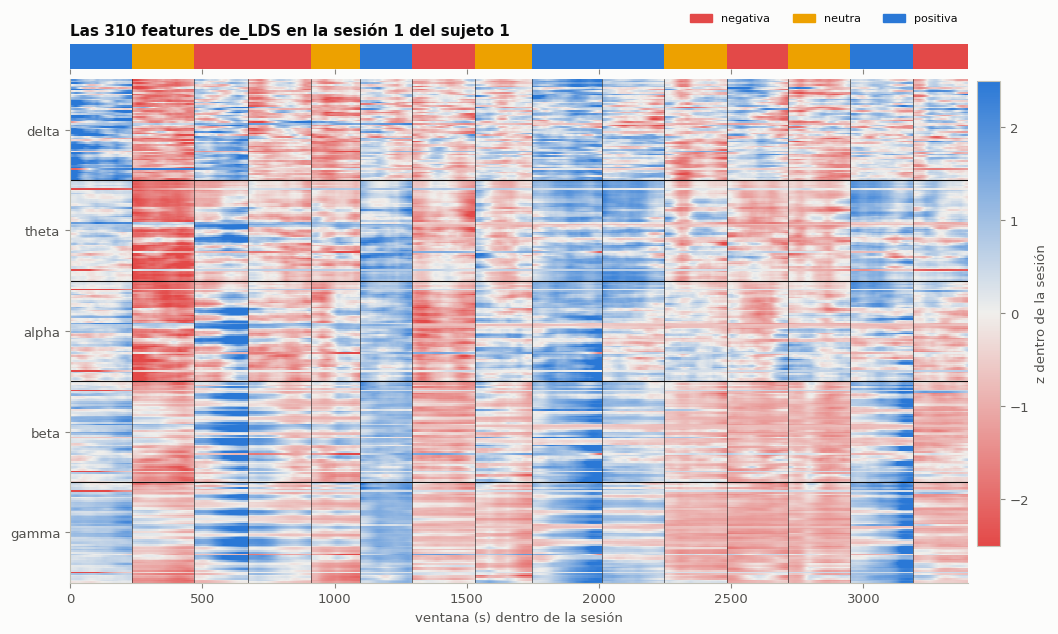

In [25]:
orden = [col(ch, b) for b in range(5) for ch in range(62)]           # banda a banda
Z11 = X[m11][:, orden]
Z11 = ((Z11 - Z11.mean(0)) / Z11.std(0)).T

fig, (a0, a1) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw={"height_ratios": [1, 20], "hspace": 0.04})
fondo_clases(a0, y11, alpha=1)
a0.set_yticks([]); a0.grid(False); a0.spines[:].set_visible(False)
a0.set_title("Las 310 features de_LDS en la sesión 1 del sujeto 1", pad=6)
im = a1.imshow(Z11, aspect="auto", cmap=DIV, vmin=-2.5, vmax=2.5, interpolation="nearest",
               extent=(0, Z11.shape[1], 310, 0))
for b in range(1, 5):
    a1.axhline(62 * b, color=TINTA, lw=0.8)
a1.set_yticks([31 + 62 * b for b in range(5)]); a1.set_yticklabels(NB)
for x0 in cambios[1:]:
    a1.axvline(x0, color=TINTA, lw=0.4)
a1.grid(False)
a1.set_xlabel("ventana (s) dentro de la sesión")
cb = fig.colorbar(im, ax=[a0, a1], pad=0.01, fraction=0.025); cb.set_label("z dentro de la sesión")
leyenda_clases(a0, loc="lower right", bbox_to_anchor=(1.0, 1.4), ncol=3, fontsize=8)
guardar(fig, "15_heatmap_310_features")
plt.show()

- **En beta y gamma (abajo), los clips positivos son bloques azules muy claros en casi todos los canales a la vez.** La diferencia es global, aunque más fuerte en los temporales.
- **En delta, theta y alpha el patrón es más irregular**: cambia de un clip a otro sin seguir tanto a la emoción.
- **Cada clip tiene su propia "firma"** (los bloques verticales). Esto confirma que la unidad real de variación es el trial.

## 6. Diferencias entre emociones (todos los sujetos)

Para comparar emociones entre personas distintas se normaliza **cada sujeto con su propia media y desviación** (`zscore_per_subject`, lo mismo que en los experimentos 02-04). Así un valor de +0.5 significa "medio desvío por encima de lo normal **para esa persona**".

Después se promedia cada emoción dentro de cada sujeto, y luego entre sujetos. Las barras de error son el intervalo de confianza del 95 % entre los 15 sujetos.

In [26]:
Z = d.zscore_per_subject(X, suj).astype(np.float32)
SUJ = np.arange(1, 16)
# M[s, c, f]: media de la feature f para el sujeto s en la emocion c
M = np.stack([np.stack([Z[(suj == s) & (y == c)].mean(0) for c in CLASES]) for s in SUJ])
print(M.shape)

(15, 3, 310)


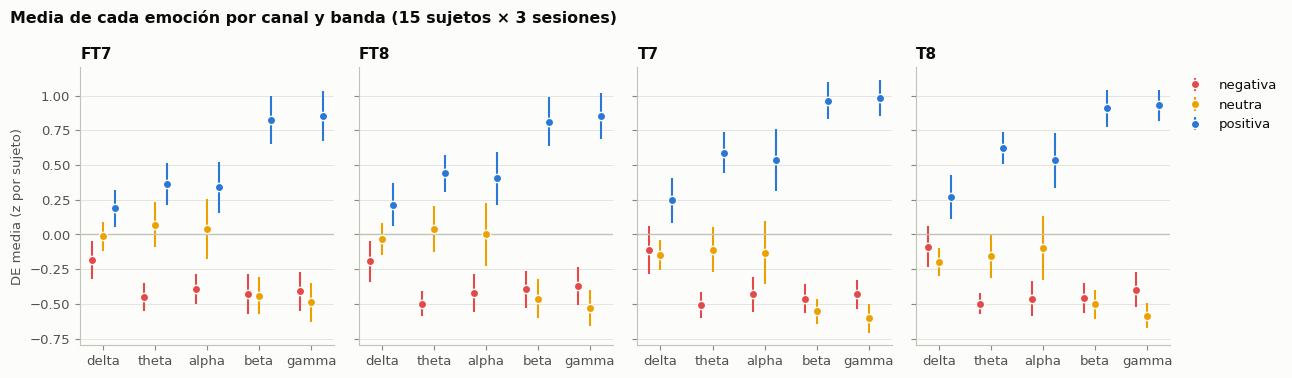

In [27]:
fig, axs = plt.subplots(1, 4, figsize=(13, 3.8), sharey=True)
xb = np.arange(5)
for ax, ch, nombre in zip(axs, CH4, cfg.CHANNEL_NAMES):
    for k, c in enumerate(CLASES):
        v = M[:, c, [col(ch, b) for b in range(5)]]
        ax.errorbar(xb + (k - 1) * 0.22, v.mean(0), yerr=1.96 * v.std(0, ddof=1) / np.sqrt(15),
                    fmt="o", ms=6, color=COLOR[c], ecolor=COLOR[c], elinewidth=1.5, capsize=0,
                    label=NOMBRE[c], mec=SUP, mew=1)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_xticks(xb); ax.set_xticklabels(NB)
    ax.set_title(nombre)
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("DE media (z por sujeto)")
axs[-1].legend(loc="upper left", bbox_to_anchor=(1, 1))
fig.suptitle("Media de cada emoción por canal y banda (15 sujetos × 3 sesiones)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "16_media_por_emocion_4canales")
plt.show()

El patrón es muy parecido en los 4 canales:

- **Positiva**: por encima de lo normal en todas las bandas, y mucho en beta y gamma (unas +0.8 a +1 desviaciones típicas).
- **Neutra y negativa**: por debajo en beta y gamma, y **casi iguales entre sí** en esas bandas. Se diferencian algo en theta y alpha: la negativa está más baja (unas −0.5, frente a unas 0 de la neutra).
- **T7 y T8 separan algo más que FT7 y FT8.**

Los intervalos de positiva y de las otras dos clases no se tocan. En cambio, los de neutra y negativa se solapan en beta y gamma. Para separar esas dos, el modelo tiene que apoyarse en theta y alpha, donde las diferencias son pequeñas.

### 6.1 Mapas de la cabeza: dónde se ve cada emoción

Cada mapa es la media de la emoción en los 62 electrodos (z por sujeto, promediado en los 15 sujetos), interpolada sobre la cabeza. **Azul = más energía de lo normal para esa persona; rojo = menos.** Los círculos negros son FT7, FT8, T7 y T8.

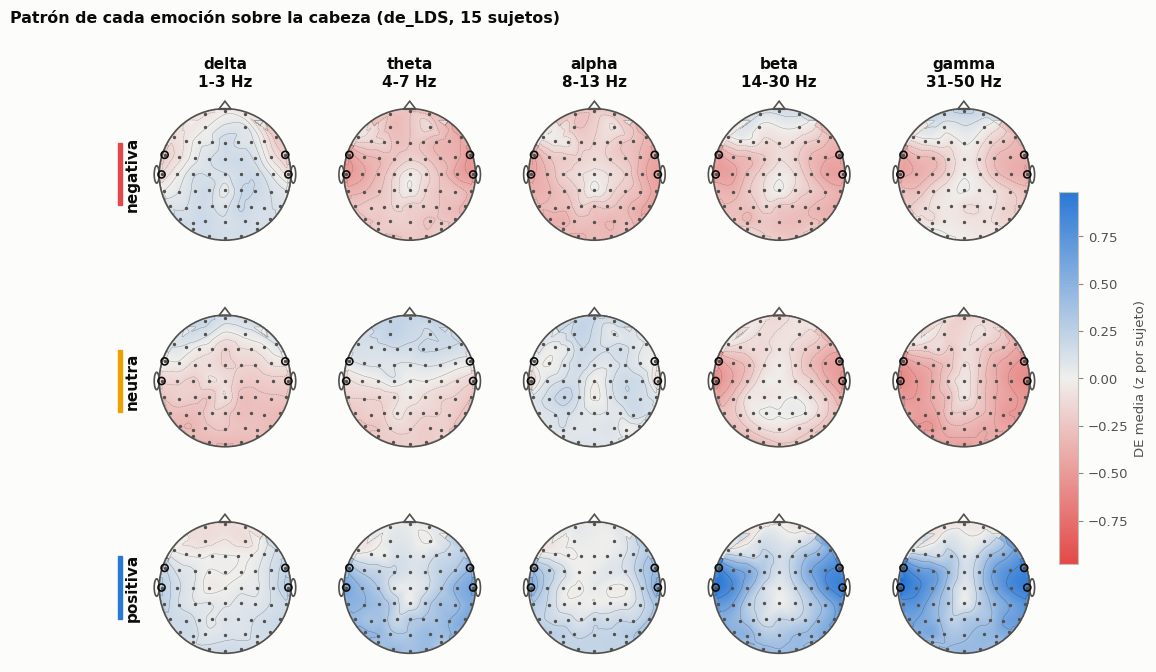

In [28]:
Mm = M.mean(0)                                           # (3, 310)
lim = np.abs(Mm).max()
fig, axs = plt.subplots(3, 5, figsize=(12, 7.6))
for i, c in enumerate([0, 1, 2]):
    for b in range(5):
        im = topomap(axs[i, b], Mm[c, [col(ch, b) for ch in range(62)]], -lim, lim, DIV)
        if i == 0:
            axs[i, b].set_title(f"{NB[b]}\n{BANDAS[NB[b]][0]}-{BANDAS[NB[b]][1]} Hz", loc="center")
    axs[i, 0].text(-0.75, 0, NOMBRE[c], rotation=90, va="center", ha="center", fontsize=11, fontweight="bold")
    axs[i, 0].add_patch(Rectangle((-0.86, -0.25), 0.03, 0.5, color=COLOR[c], clip_on=False))
cb = fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02); cb.set_label("DE media (z por sujeto)")
fig.suptitle("Patrón de cada emoción sobre la cabeza (de_LDS, 15 sujetos)", x=0.01, ha="left", fontweight="bold")
guardar(fig, "17_topomapas_por_emocion")
plt.show()

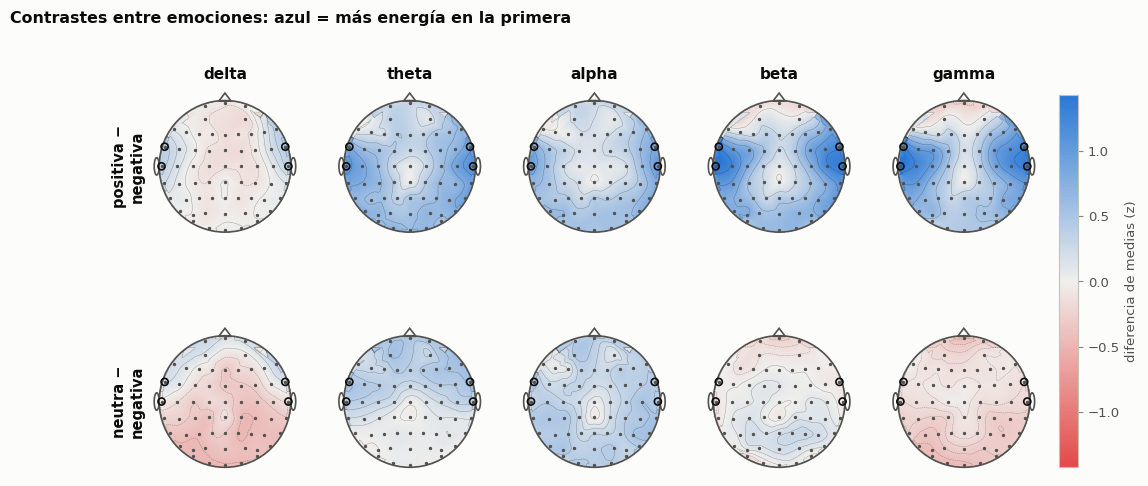

Las 10 features con más diferencia positiva - negativa:
    T7 beta   +1.43
    T7 gamma  +1.41
    T8 beta   +1.36
    T8 gamma  +1.33
   FT7 gamma  +1.26
   FT7 beta   +1.25
    C5 beta   +1.24
   FT8 gamma  +1.22
    C5 gamma  +1.22
    C6 beta   +1.21


In [29]:
# Contrastes directos: positiva - negativa y neutra - negativa (misma escala)
dif = Mm[2] - Mm[0]
dif_nn = Mm[1] - Mm[0]
lim2 = np.abs(dif).max()
fig, axs = plt.subplots(2, 5, figsize=(12, 5.6))
for i, (v, nombre) in enumerate([(dif, "positiva −\nnegativa"), (dif_nn, "neutra −\nnegativa")]):
    for b in range(5):
        im = topomap(axs[i, b], v[[col(ch, b) for ch in range(62)]], -lim2, lim2, DIV)
        if i == 0:
            axs[i, b].set_title(NB[b], loc="center")
    axs[i, 0].text(-0.78, 0, nombre, rotation=90, va="center", ha="center", fontsize=10.5, fontweight="bold")
cb = fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02); cb.set_label("diferencia de medias (z)")
fig.suptitle("Contrastes entre emociones: azul = más energía en la primera", x=0.01, ha="left", fontweight="bold")
guardar(fig, "18_topomapa_contrastes")
plt.show()

top = np.argsort(-np.abs(dif))[:10]
print("Las 10 features con más diferencia positiva - negativa:")
for f in top:
    print(f"  {CANALES[f // 5]:>4} {NB[f % 5]:<6} {dif[f]:+.2f}")

**Dónde se ve cada emoción**

- **Positiva**: mucha más beta y gamma en las **zonas temporales laterales**, a izquierda y derecha, justo donde están los 4 electrodos del TFG. Theta y alpha también algo más altas.
- **Neutra**: beta y gamma más bajas en los temporales, y alpha y theta un poco más altas en toda la cabeza.
- **Negativa**: theta y alpha más bajas en general, y algo más de delta en la parte de atrás (parietal-occipital). En el contraste neutra − negativa, delta sale roja atrás, así que la negativa tiene ahí más delta.

En lo esencial coincide con lo publicado para SEED. Zheng, Zhu & Lu (2019) describen:

- más beta y gamma temporal lateral en las emociones positivas;
- más alpha parietal-occipital en las neutras;
- más delta parietal-occipital en las negativas.

**Las 10 features que más separan positiva de negativa son todas beta o gamma de canales temporales** (T7, T8, FT7, FT8) o vecinos (C5, C6).

### 6.2 ¿Es igual en todos los sujetos?

La diferencia media puede esconder que en unos sujetos va en un sentido y en otros al revés. Abajo, para la feature de los 4 canales que más separa positiva de negativa, la diferencia en **cada sujeto y sesión** (45 puntos).

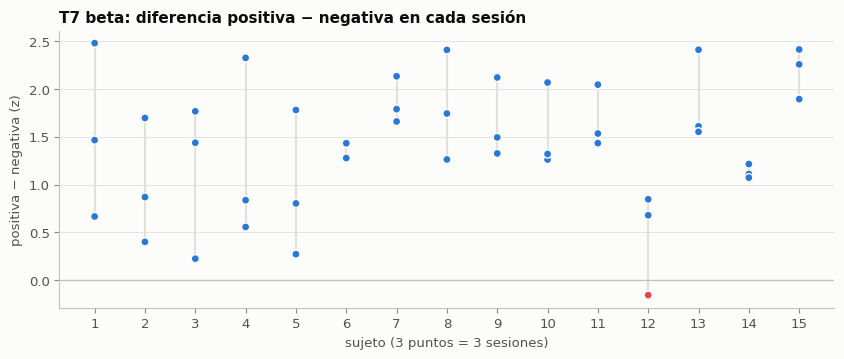

T7 beta: positiva > negativa en 44 de 45 sesiones; sujetos con las 3 sesiones a favor: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 14, 15]


In [30]:
f20 = [col(ch, b) for ch in CH4 for b in range(5)]
fbest = f20[int(np.argmax(np.abs(dif[f20])))]
nombre_f = f"{CANALES[fbest // 5]} {NB[fbest % 5]}"
D = np.array([[Z[(suj == s) & (ses == k) & (y == 2), fbest].mean() - Z[(suj == s) & (ses == k) & (y == 0), fbest].mean()
               for k in (1, 2, 3)] for s in SUJ])

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axhline(0, color="#c3c2b7", lw=1)
for s in SUJ:
    ax.plot([s] * 3, D[s - 1], color=GRID, lw=1.5, zorder=1)
    ax.scatter([s] * 3, D[s - 1], s=34, color=np.where(D[s - 1] > 0, COLOR[2], COLOR[0]), edgecolor=SUP, lw=1, zorder=2)
ax.set_xticks(SUJ)
ax.set_xlabel("sujeto (3 puntos = 3 sesiones)")
ax.set_ylabel("positiva − negativa (z)")
ax.set_title(f"{nombre_f}: diferencia positiva − negativa en cada sesión")
ax.grid(axis="x", visible=False)
guardar(fig, "19_consistencia_sujetos")
plt.show()
print(f"{nombre_f}: positiva > negativa en {(D > 0).sum()} de 45 sesiones; "
      f"sujetos con las 3 sesiones a favor: {[int(s) for s in SUJ if (D[s - 1] > 0).all()]}")

- **T7 beta es mayor en las positivas que en las negativas en 44 de las 45 sesiones.** La única excepción es una sesión del sujeto 12.
- **El efecto va en la misma dirección en todas las personas**; lo que cambia es su tamaño, de unas 0.2 a unas 2.5 desviaciones típicas.

Por esto el modelo cross-subject puede funcionar con sujetos nuevos, al menos para reconocer la emoción positiva.

## 7. ¿Qué features distinguen mejor las emociones?

Para medir cuánto separa cada feature las 3 emociones se usa el **estadístico F del ANOVA** (varianza entre clases / varianza dentro de cada clase): cuanto mayor, mejor separa.

Se calcula sobre la **media de cada trial** (45 sesiones × 15 trials = 675 muestras), no sobre ventanas sueltas: como las ventanas de un trial son casi idénticas (sección 4.3), contarlas como independientes inflaría F artificialmente.

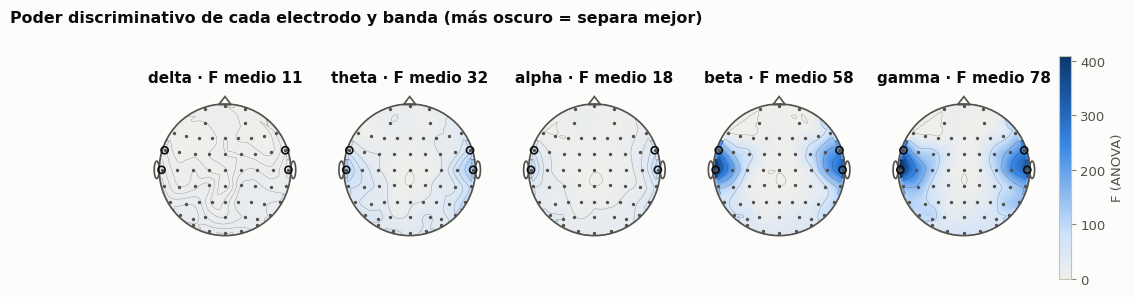

Top 15 de las 310 features:
    1.   T7 gamma  F =  409.5  <- canal del TFG
    2.   T7 beta   F =  379.8  <- canal del TFG
    3.   T8 gamma  F =  329.2  <- canal del TFG
    4.   T8 beta   F =  303.4  <- canal del TFG
    5.  FT8 gamma  F =  249.1  <- canal del TFG
    6.  FT7 gamma  F =  247.6  <- canal del TFG
    7.   C6 gamma  F =  236.4
    8.   C5 gamma  F =  234.4
    9.  FT7 beta   F =  224.8  <- canal del TFG
   10.  FT8 beta   F =  212.0  <- canal del TFG
   11.   C5 beta   F =  204.5
   12.   C6 beta   F =  193.0
   13.  FC6 gamma  F =  178.9
   14.  TP8 gamma  F =  175.3
   15.  FC6 beta   F =  172.0

Las 20 features del TFG (4 canales × 5 bandas), con su puesto entre 310:
    1.   T7 gamma  F =  409.5
    2.   T7 beta   F =  379.8
    3.   T8 gamma  F =  329.2
    4.   T8 beta   F =  303.4
    5.  FT8 gamma  F =  249.1
    6.  FT7 gamma  F =  247.6
    9.  FT7 beta   F =  224.8
   10.  FT8 beta   F =  212.0
   21.   T8 theta  F =  133.4
   24.   T7 theta  F =  113.1
   4

In [31]:
inicios = np.r_[0, np.flatnonzero(np.diff(tid)) + 1]
n_v = np.diff(np.r_[inicios, len(tid)])
Zt = np.add.reduceat(Z.astype(np.float64), inicios, axis=0) / n_v[:, None]        # (675, 310)
Xt = np.add.reduceat(X.astype(np.float64), inicios, axis=0) / n_v[:, None]
yt, st, sest = y[inicios], suj[inicios], ses[inicios]
F, p = f_classif(Zt, yt)
rank = np.argsort(-F)

fig, axs = plt.subplots(1, 5, figsize=(12, 2.9))
vmax = F.max()
for b in range(5):
    im = topomap(axs[b], F[[col(ch, b) for ch in range(62)]], 0, vmax, SEQ)
    axs[b].set_title(f"{NB[b]} · F medio {F[b::5].mean():.0f}", loc="center")
cb = fig.colorbar(im, ax=axs, fraction=0.02, pad=0.02); cb.set_label("F (ANOVA)")
fig.suptitle("Poder discriminativo de cada electrodo y banda (más oscuro = separa mejor)", x=0.01, ha="left", fontweight="bold", y=1.04)
guardar(fig, "20_topomapa_F")
plt.show()

pos_rank = {f: int(np.where(rank == f)[0][0]) + 1 for f in range(310)}
print("Top 15 de las 310 features:")
for f in rank[:15]:
    marca = "  <- canal del TFG" if f // 5 in CH4 else ""
    print(f"  {pos_rank[f]:>3}. {CANALES[f // 5]:>4} {NB[f % 5]:<6} F = {F[f]:6.1f}{marca}")
print("\nLas 20 features del TFG (4 canales × 5 bandas), con su puesto entre 310:")
for f in sorted(f20, key=lambda f: pos_rank[f]):
    print(f"  {pos_rank[f]:>3}. {CANALES[f // 5]:>4} {NB[f % 5]:<6} F = {F[f]:6.1f}")

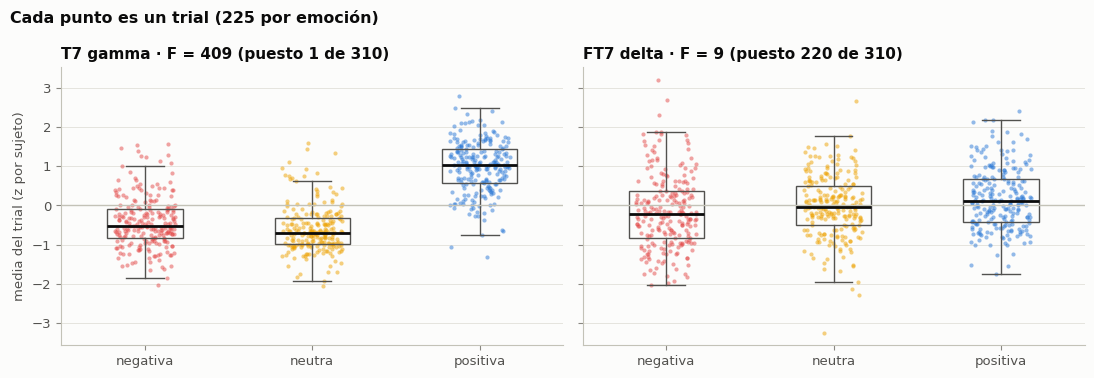

In [32]:
# Distribucion de la feature mas y menos discriminativa de las 20 del TFG
f_mejor = min(f20, key=lambda f: pos_rank[f])
f_peor = max(f20, key=lambda f: pos_rank[f])
rng = np.random.default_rng(0)
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, f in zip(axs, [f_mejor, f_peor]):
    for k, c in enumerate(CLASES):
        v = Zt[yt == c, f]
        ax.boxplot(v, positions=[k], widths=0.45, showfliers=False, patch_artist=True,
                   boxprops=dict(facecolor="none", edgecolor=TINTA2), medianprops=dict(color=TINTA, lw=2),
                   whiskerprops=dict(color=TINTA2), capprops=dict(color=TINTA2))
        ax.scatter(k + rng.uniform(-0.18, 0.18, v.size), v, s=9, alpha=0.5, color=COLOR[c], lw=0)
    ax.axhline(0, color="#c3c2b7", lw=1)
    ax.set_xticks(range(3)); ax.set_xticklabels([NOMBRE[c] for c in CLASES])
    ax.set_title(f"{CANALES[f // 5]} {NB[f % 5]} · F = {F[f]:.0f} (puesto {pos_rank[f]} de 310)")
    ax.grid(axis="x", visible=False)
axs[0].set_ylabel("media del trial (z por sujeto)")
fig.suptitle("Cada punto es un trial (225 por emoción)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
guardar(fig, "21_distribucion_mejor_peor")
plt.show()

### 7.1 ¿Qué pares de emociones son fáciles de separar?

F mide la separación de las 3 clases a la vez. Para ver cada par por separado se usa el **tamaño del efecto d de Cohen** (diferencia de medias dividida por la desviación típica conjunta) en las medias de trial. Como referencia: |d| ≈ 0.2 es pequeño, 0.5 mediano y ≥ 0.8 grande.

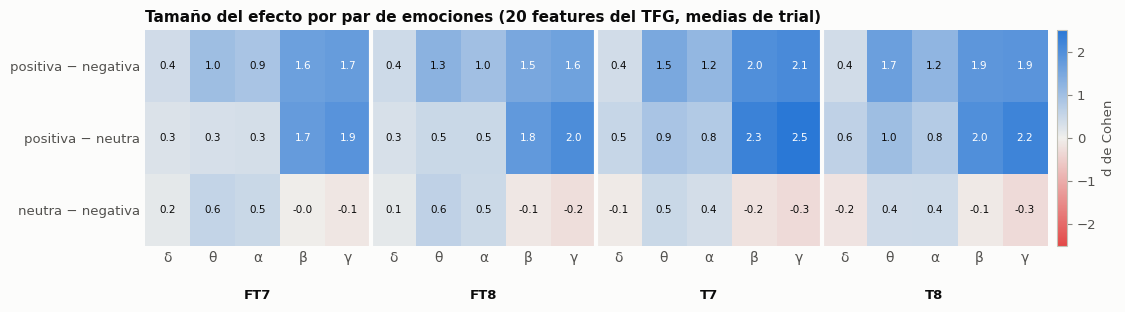

positiva − negativa: |d| máximo 2.10 (T7 gamma)
positiva − neutra  : |d| máximo 2.50 (T7 gamma)
  neutra − negativa: |d| máximo 0.61 (FT8 theta)


In [33]:
def cohen_d(a, b):
    sp = np.sqrt(((a.size - 1) * a.var(ddof=1) + (b.size - 1) * b.var(ddof=1)) / (a.size + b.size - 2))
    return (a.mean() - b.mean()) / sp

pares = [(2, 0), (2, 1), (1, 0)]
f20_ord = [col(ch, b) for ch in CH4 for b in range(5)]
Dd = np.array([[cohen_d(Zt[yt == a, f], Zt[yt == b, f]) for f in f20_ord] for a, b in pares])

fig, ax = plt.subplots(figsize=(12, 2.8))
lim_d = np.abs(Dd).max()
im = ax.imshow(Dd, cmap=DIV, vmin=-lim_d, vmax=lim_d, aspect="auto")
for i in range(3):
    for j in range(20):
        ax.text(j, i, f"{Dd[i, j]:.1f}", ha="center", va="center", fontsize=7.5,
                color="white" if abs(Dd[i, j]) > 0.6 * lim_d else TINTA)
ax.set_yticks(range(3)); ax.set_yticklabels([f"{NOMBRE[a]} − {NOMBRE[b]}" for a, b in pares])
ax.set_xticks(range(20)); ax.set_xticklabels([GRIEGA[NB[b]] for _ in CH4 for b in range(5)], fontsize=10)
for k, nombre in enumerate(cfg.CHANNEL_NAMES):
    ax.text(k * 5 + 2, -0.2, nombre, ha="center", va="top", fontsize=9.5, fontweight="bold",
            transform=ax.get_xaxis_transform())
    if k:
        ax.axvline(k * 5 - 0.5, color=SUP, lw=3)
ax.grid(False); ax.spines[:].set_visible(False); ax.tick_params(length=0)
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01); cb.set_label("d de Cohen")
ax.set_title("Tamaño del efecto por par de emociones (20 features del TFG, medias de trial)")
guardar(fig, "21b_cohen_d_pares")
plt.show()
for (a, b), fila in zip(pares, Dd):
    j = int(np.argmax(np.abs(fila)))
    print(f"{NOMBRE[a]:>8} − {NOMBRE[b]:<8}: |d| máximo {abs(fila[j]):.2f} ({cfg.CHANNEL_NAMES[j // 5]} {NB[j % 5]})")

**Este es el resultado más útil para entender los errores de los modelos.**

- **Positiva frente a las otras dos**: efectos enormes en beta y gamma (d de 1.5 a 2.5). Reconocer la positiva es fácil.
- **Neutra frente a negativa**: el efecto máximo es d ≈ 0.6, en theta de FT7/FT8, y en beta y gamma es prácticamente cero. Con estos 4 canales, neutra y negativa se parecen mucho.

Las matrices de confusión de `results/` lo confirman: la confusión entre neutra y negativa es el error más frecuente.

- En el exp. 01 (ANN, 4 canales, semilla 0) es el 60 % de los errores.
- En el exp. 02 (ANN cross-subject, 4 canales, semilla 0) es el 48 % de los errores.

- **Las 6 features más discriminativas de las 310 son de los 4 canales del TFG** (gamma y beta de T7, T8, FT8 y FT7). Las 8 features beta/gamma del TFG están entre las 10 primeras. Esto respalda con datos la elección de FT7, FT8, T7 y T8.
- **Por bandas, el F medio ordena así: gamma (78) > beta (58) > theta (32) > alpha (18) > delta (11).** Las features delta del TFG están entre los puestos 159 y 220, así que aportan poco.
- **En las cajas**, T7 gamma (izquierda) separa claramente la positiva, pero neutra y negativa siguen solapadas. En FT7 delta (derecha) las tres emociones se solapan casi por completo.
- **Esto ayuda a explicar por qué 62 canales mejoran poco a 4** (+2.7 puntos en el exp. 02). La información útil está concentrada en la zona temporal, y el resto de canales en buena parte la repiten.

## 8. Sujetos y sesiones: por qué el cross-subject es difícil

### 8.1 Cada persona tiene su propio nivel

Sin normalizar, la DE de un mismo electrodo cambia mucho de una persona a otra (grosor del cráneo, impedancia de los electrodos, colocación del gorro...). Abajo, la DE cruda de la mejor feature de los 4 canales: las cajas son la distribución de cada sujeto y los puntos de colores, la media de cada emoción.

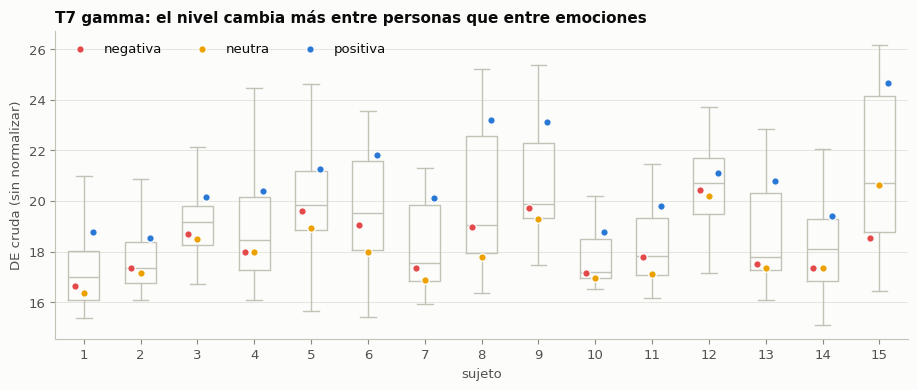

Fracción de la varianza de las 310 features (medias de trial) explicada por...
  el sujeto  (datos crudos)     : 54.7%
  la emoción (datos crudos)     : 3.1%
  la emoción (z-score por sujeto): 9.0%


In [34]:
fig, ax = plt.subplots(figsize=(11, 4))
for s in SUJ:
    v = X[suj == s, f_mejor]
    ax.boxplot(v, positions=[s], widths=0.55, showfliers=False,
               boxprops=dict(color="#c3c2b7"), medianprops=dict(color="#c3c2b7"),
               whiskerprops=dict(color="#c3c2b7"), capprops=dict(color="#c3c2b7"))
    for k, c in enumerate(CLASES):
        ax.scatter(s + (k - 1) * 0.16, X[(suj == s) & (y == c), f_mejor].mean(), s=30,
                   color=COLOR[c], edgecolor=SUP, lw=1, zorder=3, label=NOMBRE[c] if s == 1 else None)
ax.set_xticks(SUJ); ax.set_xlabel("sujeto")
ax.set_ylabel("DE cruda (sin normalizar)")
ax.set_title(f"{CANALES[f_mejor // 5]} {NB[f_mejor % 5]}: el nivel cambia más entre personas que entre emociones")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left", ncol=3)
guardar(fig, "22_diferencias_entre_sujetos")
plt.show()

def eta2(A, g):
    # Fraccion de la varianza de cada columna explicada por el grupo g
    tot = ((A - A.mean(0)) ** 2).sum(0)
    entre = sum((g == k).sum() * (A[g == k].mean(0) - A.mean(0)) ** 2 for k in np.unique(g))
    return entre / tot

print("Fracción de la varianza de las 310 features (medias de trial) explicada por...")
print(f"  el sujeto  (datos crudos)     : {eta2(Xt, st).mean():.1%}")
print(f"  la emoción (datos crudos)     : {eta2(Xt, yt).mean():.1%}")
print(f"  la emoción (z-score por sujeto): {eta2(Zt, yt).mean():.1%}")

### 8.2 Canales ruidosos

En la sección 3 se vio que en la sesión 1 del sujeto 1 había canales rotos (P1, PO6). SEED no elimina ni interpola canales malos, así que esos canales llegan tal cual a las features. Para revisarlo en las 45 sesiones sin cargar los 7 GB de EEG, se usa la DE gamma media de cada canal en la sesión, menos la mediana de los 62 canales de esa sesión: un canal muy por encima del resto suele tener ruido o mal contacto.

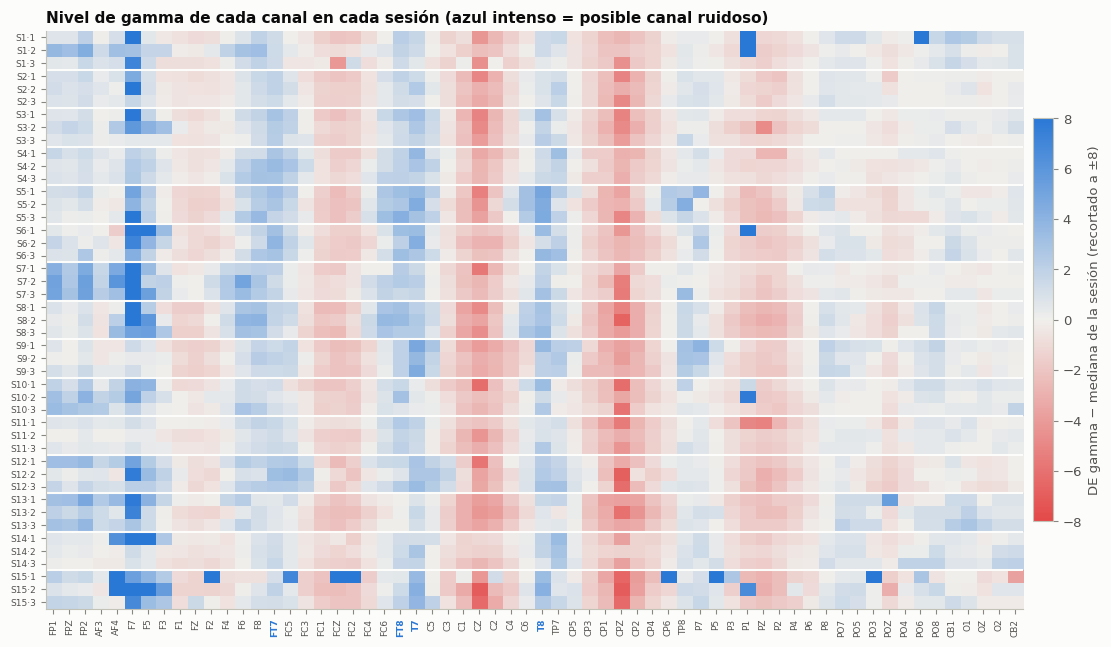

Pares sesión-canal con gamma > 4 por encima de la mediana: 76
Canales más afectados: [('F7', 27), ('F5', 8), ('FP2', 6), ('P1', 5), ('T7', 5), ('AF4', 5), ('T8', 4), ('FP1', 3)]
Sesiones con más canales afectados: [('S15·1', 9), ('S15·2', 7), ('S7·2', 5), ('S7·1', 4)]
Los 4 canales del TFG: entre -0.1 y +4.9 respecto a la mediana (media +2.1) · CZ: media -3.7


In [35]:
G = X[:, 4::5]                                            # DE gamma de los 62 canales
claves_ses = [(s, k) for s in SUJ for k in (1, 2, 3)]
DEV = np.array([G[(suj == s) & (ses == k)].mean(0) for s, k in claves_ses])
DEV = DEV - np.median(DEV, axis=1, keepdims=True)

fig, ax = plt.subplots(figsize=(13, 7.5))
im = ax.imshow(DEV, cmap=DIV, vmin=-8, vmax=8, aspect="auto", interpolation="nearest")
ax.set_xticks(range(62)); ax.set_xticklabels(CANALES, rotation=90, fontsize=6.5)
for j in CH4:
    ax.get_xticklabels()[j].set_fontweight("bold"); ax.get_xticklabels()[j].set_color("#2a78d6")
ax.set_yticks(range(45)); ax.set_yticklabels([f"S{s}·{k}" for s, k in claves_ses], fontsize=6.5)
for i in range(3, 45, 3):
    ax.axhline(i - 0.5, color=SUP, lw=1.5)
ax.grid(False)
cb = fig.colorbar(im, ax=ax, fraction=0.02, pad=0.01); cb.set_label("DE gamma − mediana de la sesión (recortado a ±8)")
ax.set_title("Nivel de gamma de cada canal en cada sesión (azul intenso = posible canal ruidoso)")
guardar(fig, "22b_canales_ruidosos")
plt.show()

malos = [(claves_ses[i], CANALES[j], DEV[i, j]) for i, j in np.argwhere(DEV > 4)]
from collections import Counter
print(f"Pares sesión-canal con gamma > 4 por encima de la mediana: {len(malos)}")
print("Canales más afectados:", Counter(c for _, c, _ in malos).most_common(8))
print("Sesiones con más canales afectados:", Counter(f"S{s}·{k}" for (s, k), _, _ in malos).most_common(4))
print(f"Los 4 canales del TFG: entre {DEV[:, CH4].min():+.1f} y {DEV[:, CH4].max():+.1f} respecto a la mediana "
      f"(media {DEV[:, CH4].mean():+.1f}) · CZ: media {DEV[:, CANALES.index('CZ')].mean():+.1f}")

- **F7 es el canal más problemático**: tiene gamma muy alta en 27 de las 45 sesiones. Está en el borde frontal-temporal, cerca del ojo y del músculo temporal. También fallan FP1, FP2, AF4 y F5 (ojos y frente), y P1 en algunas sesiones.
- **La sesión 1 del sujeto 15 tiene 9 canales con ruido.** Es el grupo que aparece separado en la PCA de abajo.
- **Los 4 canales del TFG no están rotos en ninguna sesión**, pero siempre tienen más gamma que la mediana (+2.1 de media). Es otra pista de la contribución muscular de la sección 3.2.
- **CZ tiene siempre la gamma más baja (−3.7 de media).** Encaja con que sea casi plano.
- **En los modelos de 62 canales, estos canales ruidosos entran como features.** El z-score por sujeto lo atenúa, pero no lo corrige si el ruido solo aparece en una de las sesiones.

### 8.3 Todos los trials en 2 dimensiones (PCA)

Cada punto es un trial (675), proyectado en las 2 direcciones de mayor varianza de las 310 features. A la izquierda los datos crudos, con el número de cada sujeto en el centro de sus trials; a la derecha, tras normalizar por sujeto y coloreado por emoción.

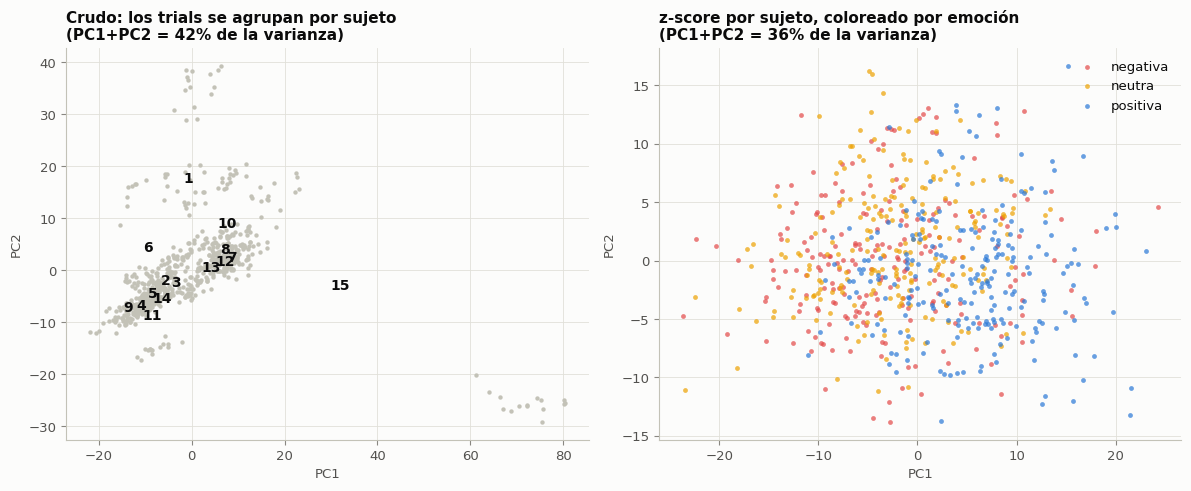

Trials con PC1 > 40: sesiones [(15, 1)]
Trials con PC2 > 28: sesiones [(1, 1)]


In [36]:
pca_raw = PCA(2).fit(Xt); P1 = pca_raw.transform(Xt)
pca_z = PCA(2).fit(Zt);   P2 = pca_z.transform(Zt)

fig, axs = plt.subplots(1, 2, figsize=(12, 5))
axs[0].scatter(*P1.T, s=10, color="#c3c2b7", lw=0)
for s in SUJ:
    cx, cy = P1[st == s].mean(0)
    axs[0].text(cx, cy, str(s), ha="center", va="center", fontsize=10, fontweight="bold", color=TINTA)
axs[0].set_title(f"Crudo: los trials se agrupan por sujeto\n(PC1+PC2 = {pca_raw.explained_variance_ratio_.sum():.0%} de la varianza)")
for c in CLASES:
    axs[1].scatter(*P2[yt == c].T, s=12, alpha=0.7, color=COLOR[c], lw=0, label=NOMBRE[c])
axs[1].set_title(f"z-score por sujeto, coloreado por emoción\n(PC1+PC2 = {pca_z.explained_variance_ratio_.sum():.0%} de la varianza)")
axs[1].legend(loc="upper right")
for ax in axs:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.tight_layout()
guardar(fig, "23_pca_trials")
plt.show()
for nombre, cond in [("PC1 > 40", P1[:, 0] > 40), ("PC2 > 28", P1[:, 1] > 28)]:
    print(f"Trials con {nombre}: sesiones {sorted({(int(a), int(b)) for a, b in zip(st[cond], sest[cond])})}")

- **Datos crudos (izquierda)**: la PCA ve sobre todo **quién es la persona** y qué sesiones tienen canales rotos. El grupo de la derecha es la sesión 1 del sujeto 15 y el de arriba, la sesión 1 del sujeto 1. Las emociones no aparecen. Según la celda de 8.1, el sujeto explica el **55 %** de la varianza de las features crudas y la emoción solo el **3 %**.
- **Con z-score por sujeto (derecha)**: desaparecen los grupos por persona y la emoción pasa a explicar el **9 %** de la varianza. Las positivas tienden hacia la derecha, pero las tres clases siguen mezcladas. La emoción no es la dirección de mayor varianza, así que el clasificador tiene que encontrar direcciones concretas (beta y gamma temporal).

Por eso la normalización por sujeto es imprescindible en el cross-subject.

### 8.4 ¿Se parecen las sesiones de una misma persona?

Para cada sesión se forma su "huella": la media de las 310 features (z por sujeto) en cada emoción, menos la media de la sesión. Se compara la huella de dos sesiones del mismo sujeto con la de dos sujetos distintos (correlación).

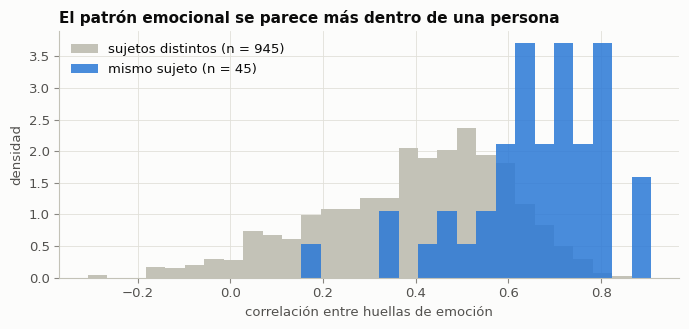

Correlación media: mismo sujeto 0.66 · sujetos distintos 0.40


In [37]:
huella = {}
for s in SUJ:
    for k in (1, 2, 3):
        m = (suj == s) & (ses == k)
        h = np.stack([Z[m & (y == c)].mean(0) for c in CLASES])
        huella[(s, k)] = (h - h.mean(0)).ravel()
claves = list(huella)
mismo, distinto = [], []
for i in range(len(claves)):
    for j in range(i + 1, len(claves)):
        r = np.corrcoef(huella[claves[i]], huella[claves[j]])[0, 1]
        (mismo if claves[i][0] == claves[j][0] else distinto).append(r)

fig, ax = plt.subplots(figsize=(8, 3.2))
bins = np.linspace(min(distinto + mismo), max(distinto + mismo), 30)
ax.hist(distinto, bins=bins, color="#c3c2b7", label=f"sujetos distintos (n = {len(distinto)})", density=True)
ax.hist(mismo, bins=bins, color="#2a78d6", alpha=0.85, label=f"mismo sujeto (n = {len(mismo)})", density=True)
ax.set_xlabel("correlación entre huellas de emoción")
ax.set_ylabel("densidad")
ax.set_title("El patrón emocional se parece más dentro de una persona")
ax.legend()
guardar(fig, "24_huellas_sesiones")
plt.show()
print(f"Correlación media: mismo sujeto {np.mean(mismo):.2f} · sujetos distintos {np.mean(distinto):.2f}")

- **Las huellas de dos sesiones de la misma persona se parecen más (r = 0.66) que las de dos personas distintas (r = 0.40).**
- **El patrón emocional tiene una parte común a todos**, por eso r > 0 entre personas, **y una parte propia de cada persona.**

Un modelo dentro del mismo sujeto (exp. 01, ~78 %) aprovecha esa parte personal; uno cross-subject (exp. 02, 62-65 %) no puede. Esto ayuda a entender la caída de unos 15 puntos entre los dos protocolos.

## 9. Resumen: datos importantes de SEED

**Estructura**

| | |
|---|---|
| Sujetos | 15 (7 M, 8 F), 3 sesiones cada uno, separadas de 1 a 4 semanas (3-4 meses en los sujetos 6 y 15) |
| Trials | 15 clips por sesión, mismo orden para todos: 5 positivos, 5 neutros y 5 negativos, de 6 películas distintas |
| Duración | 185-265 s por clip; 3394 s de EEG por sesión |
| EEG | 62 canales, 1000 Hz en bruto → 200 Hz preprocesado (filtro 0-75 Hz) |
| Features | ventanas de 1 s sin solapamiento, 5 bandas (δ 1-3, θ 4-7, α 8-13, β 14-30, γ 31-50 Hz); `de`, `psd` y asimetrías, cada una suavizada con `movingAve` o `LDS` |
| Tamaño | 152 730 ventanas × 310 features (62 canales) o × 20 (4 canales); 675 trials |
| Clases | equilibradas: 34.5 % positiva, 32.5 % neutra, 33.0 % negativa |

**Dónde se ven las emociones**

1. **La emoción positiva es fácil de ver.** Tiene mucha más potencia en beta y gamma (unos +4 dB) en las zonas **temporales laterales**, en todos los sujetos (44 de 45 sesiones en T7 beta).
2. **Neutra y negativa casi no se distinguen en beta y gamma.** Solo se separan algo en theta y alpha, que son más bajas en la negativa (d ≈ 0.6 como mucho). Es la confusión más frecuente de los modelos.
3. **A simple vista no se ve nada en el EEG en bruto.** Se ve en el espectro, en el espectrograma y, sobre todo, en las features de_LDS a lo largo de la sesión (sección 5.1).
4. **Las 6 mejores features de 310 son de FT7, FT8, T7 y T8** (beta y gamma), lo que respalda la elección de los 4 canales.

**Cuidado con...**

- **Las ventanas no son independientes.** Con LDS, dos ventanas seguidas tienen correlación 0.999. Siempre hay que separar por trial o por sujeto.
- **El sujeto pesa mucho más que la emoción** en los datos crudos: explica el 55 % de la varianza, frente al 3 %. Por eso hace falta el z-score por sujeto.
- **Hay canales ruidosos** (F7 en muchas sesiones; P1, PO6 y la sesión S15·1), que SEED no elimina. Los 4 canales del TFG están limpios.
- **Posible contaminación muscular (EMG).** La ventaja de los positivos es plana hasta 75 Hz y máxima sobre el músculo temporal, y los clips positivos son comedias. Conviene comentarlo en la memoria como limitación.
- **Las etiquetas son de la película** (todas las ventanas de un clip comparten etiqueta), y cada emoción corresponde a un tipo de película concreto.

**Referencias**

- W.-L. Zheng y B.-L. Lu, "Investigating Critical Frequency Bands and Channels for EEG-Based Emotion Recognition with Deep Neural Networks", *IEEE Trans. Autonomous Mental Development*, 7(3), 2015.
- W.-L. Zheng, J.-Y. Zhu y B.-L. Lu, "Identifying Stable Patterns over Time for Emotion Recognition from EEG", *IEEE Trans. Affective Computing*, 10(3), 2019.
- R.-N. Duan, J.-Y. Zhu y B.-L. Lu, "Differential entropy feature for EEG-based emotion classification", *IEEE/EMBS NER*, 2013.
- I. I. Goncharova, D. J. McFarland, T. M. Vaughan y J. R. Wolpaw, "EMG contamination of EEG: spectral and topographical characteristics", *Clinical Neurophysiology*, 114(9), 2003.